In [1]:
#!pip install biopython pandas matplotlib seaborn pyarrow openpyxl umap-learn plotly

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import scipy as sp
import pandas as pd
import networkx as nx
import random
import matplotlib.pyplot as plt
# import warnings filter
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)
from IPython.core.display import HTML
HTML('<style>.container { width:95% !important; }</style><style>.output_png {display: table-cell;text-align: center;vertical-align: middle;}</style>')

In [3]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="umap")

In [4]:

from amr.debiasing import (
    build_pathogen_vectors_antibiotic,
    build_pathogen_vectors_class,
    debias_amr_marginal,
)
from amr.visualization import (
    _umap_scatter,
    plot_heatmap_counts_vs_expected_antibiotic,
    plot_heatmap_counts_vs_expected_class,
    plot_heatmap_for_pathogen,
    plot_heatmap_for_pathogen_debiased,
    plot_umap_antibiotic_activity,
)


---

In [5]:
data_df = pd.read_parquet("data.parquet")
data_df

,Genus,CanonicalSpecies,n_causation,n_articles,n_sampled,pathogenic_index,embedding,anonymised_embedding,onehot_embedding,domain,kingdom,phylum,class,order,family
0,Abiotrophia,Abiotrophia defectiva,6,6,6,0.160939,"[0.018194107338786125, -0.004734894765230517, ...","[0.014040807844139636, -0.028420374651129048, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.166...",Bacteria,Bacillati,Bacillota,Bacilli,Lactobacillales,Aerococcaceae
1,Acetobacter,Acetobacter indonesiensis,1,3,3,0.000000,"[-0.021512236446142197, -0.03992129862308502, ...","[-0.0028289835900068283, -0.04833690822124481,...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae
2,Acetobacter,Acetobacter tropicalis,1,2,2,0.000000,"[-0.0070418259128928185, -0.005829853471368551...","[0.005147432442754507, -0.013049994595348835, ...","[0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae
3,Achromobacter,Achromobacter animicus,1,2,2,0.000000,"[0.011074555106461048, 0.013332720845937729, 0...","[0.012643104419112206, -0.01178667601197958, 0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae
4,Achromobacter,Achromobacter denitrificans,75,36,36,0.387804,"[0.014773702074987037, -0.004635852294159122, ...","[0.011467029051855206, -0.012983008560258896, ...","[0.04, 0.013333333333333334, 0.066666666666666...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1274,Yersinia,Yersinia enterocolitica,85,3419,200,0.654031,"[-0.009990866917788105, 0.009774883079979405, ...","[0.0024005417033656747, -0.009907858140479005,...","[0.0, 0.0, 0.0, 0.03529411764705882, 0.0, 0.0,...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1275,Yersinia,Yersinia frederiksenii,1,21,21,0.000000,"[-0.00901515781879425, 0.02502085641026497, 0....","[0.01804814115166664, 0.005011445842683315, 0....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1276,Yersinia,Yersinia pestis,124,2184,200,0.647694,"[-0.006688895473886195, 0.014983039929487154, ...","[0.011833864605177364, -0.0048193380043226024,...","[0.0, 0.0, 0.0, 0.016129032258064516, 0.0, 0.0...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1277,Yersinia,Yersinia pseudotuberculosis,88,1234,200,0.565611,"[-0.01641193700528344, 0.008593090970448842, 0...","[0.004612311640316461, -0.005791128928070644, ...","[0.011363636363636364, 0.0, 0.0113636363636363...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae


In [6]:
antibiotics_df = pd.read_excel("antibiotic_list2.xlsx")
for col in antibiotics_df.columns:
    col_list = antibiotics_df[col].values
    print(f'#{col}: {len(set(col_list))}')
antibiotics_df.head()

#Antibiotic: 245
#Class: 39
#Simplified categories: 15
#High level categories: 11
#Origin: 2


,Antibiotic,Class,Simplified categories,High level categories,Origin
0,Amikacin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
1,Arbekacin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
2,Bekanamycin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
3,Dibekacin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
4,Gentamicin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified


In [26]:
amr_df = pd.read_parquet("pmids_results_positive.parquet")
amr_df

,pathogen,antibiotic,start_date,end_date,pmids,count,venue_histogram
0,Abiotrophia defectiva,Ceftriaxone,2010/01/01,2014/12/31,[24034902],1,"{""Diagnostic microbiology and infectious disea..."
1,Abiotrophia defectiva,Ceftriaxone,2015/01/01,2019/12/31,[26666926],1,"{""Arthroplasty today"": 1, ""Antimicrobial agent..."
2,Abiotrophia defectiva,Ciprofloxacin,2010/01/01,2014/12/31,[24034902],1,"{""Diagnostic microbiology and infectious disea..."
3,Abiotrophia defectiva,Clindamycin,2015/01/01,2019/12/31,[26666926],1,"{""Antimicrobial agents and chemotherapy"": 2}"
4,Abiotrophia defectiva,Daptomycin,2015/01/01,2019/12/31,[26666926],1,"{""Antimicrobial agents and chemotherapy"": 1}"
...,...,...,...,...,...,...,...
21216,Yersinia pseudotuberculosis,Tetracycline,2020/01/01,2024/12/31,[36558790],1,"{""Pathogens (Basel, Switzerland)"": 1}"
21217,Yersinia pseudotuberculosis,Tobramycin,2020/01/01,2024/12/31,[36558790],1,"{""Pathogens (Basel, Switzerland)"": 1}"
21218,Yersinia pseudotuberculosis,Trimethoprim,1985/01/01,1989/12/31,[3914884],1,"{""Australian veterinary journal"": 1}"
21219,Yersinia pseudotuberculosis,Trimethoprim,2010/01/01,2014/12/31,[20615349],1,"{""Journal of food protection"": 1}"


In [27]:
pmid_pattern = r"(\d{4,})"  # capture group

unique_pmids = (
    amr_df["pmids"]
    .dropna()
    .astype(str)                 # ensure string dtype
    .str.extractall(pmid_pattern)[0]
    .nunique()
)

print(f"Unique PMIDs: {unique_pmids:,}")


Unique PMIDs: 25,095


In [ ]:
antibiotic = 'Amikacin'
date = ['1975/01/01','1980/01/01','1985/01/01','1990/01/01','1995/01/01','2000/01/01','2005/01/01','2010/01/01','2015/01/01','2020/01/01']
embedding_column = "anonymised_embedding"

In [25]:
_ = plot_umap_antibiotic_activity(
    data_df,
    amr_df,
    antibiotic=antibiotic,
    date=date,
    embedding_column=embedding_column,
    cmap="Reds",
    min_n_causation=3,
    max_marker_size=5,
    min_marker_size=1,
    image_size=(700,400)
)

In [11]:
mp4_path = f"timelapse_{antibiotic}.mp4"
image_size= ( 704*2, 512*2)
# Generate and display an MP4 animation for a sequence of dates
try:
    _ = plot_umap_antibiotic_activity(
        data_df,
        amr_df,
        antibiotic=antibiotic,
        date=date,
        embedding_column=embedding_column,
        cmap="Reds",
        min_n_causation=3,
        max_marker_size=7,
        min_marker_size=0.5,
        mp4_path=mp4_path,
        video_total_duration=5.0,
        video_ping_pong=False,   # set False for continuous loop
        image_size=image_size,
    )
    from IPython.display import HTML, display
    import os
    if os.path.exists(mp4_path):
        display(HTML(f'<video width="{image_size[0]}" controls loop><source src="{mp4_path}" type="video/mp4"></video>'))
    else:
        print("Animation not found; run the generation cell first.")
    print(f"Saved animation to {mp4_path}")
except ImportError as e:
    print("Install imageio, kaleido, and imageio-ffmpeg to enable animation export:", e)


Install imageio, kaleido, and imageio-ffmpeg to enable animation export: kaleido is required for figure export. Install with `pip install kaleido`.


### Debiasing via marginal interval profiles

We estimate expected resistance signal for each pathogen–antibiotic pair by isolating how each antibiotic behaves across intervals.

1. Assign every interval to a interval and compute log-damped counts
   $$L_{p,a,t} = \log(1 + C_{p,a,t}).$$
2. Aggregate the log counts across pathogens for each antibiotic (or class) to obtain its interval profile. Normalise this profile so it sums to one — this captures the typical interval distribution for that antibiotic.
3. Sum the interval-level log counts for each pathogen–antibiotic pair to obtain the total log signal
   $$L^{\text{tot}}_{p,a} = \sum_t L_{p,a,t},$$
   which reflects how much attention that pair receives overall after damping spikes.
4. Allocate the total log signal back to intervals using the antibiotic's marginal profile to obtain the expected log signal
   $$\hat{L}_{p,a,t} = L^{\text{tot}}_{p,a} \times P_{a,t}.$$
5. Convert the expected log signal to the count scale with
   $$\exp(\hat{L}_{p,a,t}) - 1$$
   to obtain the expected publication count per interval.
6. Analyse the log-space residuals
   $$R_{p,a,t} = L_{p,a,t} - \hat{L}_{p,a,t}$$
   to highlight intervals where the pair appears more or less often than the antibiotic's historical pattern suggests.

In the heatmaps we annotate each cell with the observed and expected counts, and colour by the residual in log space.




In [12]:
marg_ab, marg_cl = debias_amr_marginal(amr_df, antibiotics_df)


### Pathogen vector representations

The helpers below compress each pathogen into a normalised log-residual vector
at the antibiotic and class levels, alongside total log-count weights.


In [13]:
pathogen_names_ab, pathogen_log_sums_ab, pathogen_vectors_ab = build_pathogen_vectors_antibiotic(
    amr_df,
    antibiotics_df,
)

pathogen_names_cl, pathogen_log_sums_cl, pathogen_vectors_cl = build_pathogen_vectors_class(
    amr_df,
    antibiotics_df,
)

pathogen_vectors_ab.shape, pathogen_vectors_cl.shape



((411, 1860), (411, 370))

### UMAP scatter plots

Two-dimensional UMAP projections for antibiotic and class vectors, coloured by pathogen genus.


In [14]:
fig_ab = _umap_scatter(
    pathogen_names_ab,
    pathogen_log_sums_ab,
    pathogen_vectors_ab,
    title="UMAP projection of pathogens (antibiotic space)",
    marker_max_size=10,
    figure_size=(800, 600),
    color_map="Rainbow",
    min_size=50.0,
)
fig_ab



In [15]:
fig_cl = _umap_scatter(
    pathogen_names_cl,
    pathogen_log_sums_cl,
    pathogen_vectors_cl,
    title="UMAP projection of pathogens (class space)",
    min_size=0.0,
)
fig_cl



### Next steps: forecasting counts from embeddings

**Goal:** produce pathogen–antibiotic (and class-level) count forecasts for a future decade by combining forecasts of global antibiotic behaviour with pathogen-specific residual structure, while denormalising using observed totals from training.

1. **Forecast antibiotic/class marginal profiles.**  Fit a simple linear trend (or polynomial with regularisation) on each antibiotic’s decade-wise marginal signal $P_{a,t}$ to extrapolate $P_{a,t+1}$.  We treat these projections as scaled intensity factors rather than probabilities, so no renormalisation step is required even if total mass shifts.
2. **Assemble training targets in normalised form.**  Continue using the residual embeddings (normalised log differences) derived from observed data so the model learns deviations relative to the historical marginal behaviour.
3. **Model pathogen residual vectors.**  Train a gradient-boosted model (e.g. LightGBM/XGBoost) that consumes a window of the past $k$ decades (concatenated embeddings, optional covariates) and predicts the residual pattern for the next decade $R_{p,a,t+1}$.  Because the data are detrended, learning joint temporal patterns across pathogens should generalise across periods.
4. **Reconstruct predicted log signals.**  Combine the extrapolated marginal scale and the predicted residuals to produce normalised log values for the future decade.  Instead of forecasting new totals, re-introduce scale by multiplying with the observed totals from the latest available decade (or another chosen reference).
5. **Recover counts.**  Apply $\exp(\hat{L}_{p,a,t+1}) - 1$ to obtain count estimates, clip negatives, and optionally round.  Because we anchored to historical totals, the resulting sums reflect past magnitude while accommodating new marginal trends.

**Implementation plan:**
- Build decade-wise panels for antibiotic/class marginals, pathogen totals, and residual embeddings (training features/targets).
- Prototype the linear-trend extrapolators (`numpy.polyfit`/`LinearRegression`) for the marginal signals; inspect whether extrapolated values remain in plausible ranges without renormalisation.
- Train and validate gradient-boosted models that take $k$-decade windows of residual embeddings (plus metadata) and predict the next-decade residuals; tune $k$ and feature engineering for best generalisation.
- Integrate the reconstruction workflow that reuses observed totals for de-normalisation; back-test on held-out decades to measure reconstruction error relative to ground truth counts.
- Package the pipeline into reusable helpers/notebook cells to enable rapid experimentation with alternative temporal models or denormalisation baselines.



In [16]:
pathogen = 'Neisseria gonorrhoeae'

In [17]:
pathogen = 'Mycobacterium senegalense'

In [18]:
pathogen = 'Staphylococcus aureus'

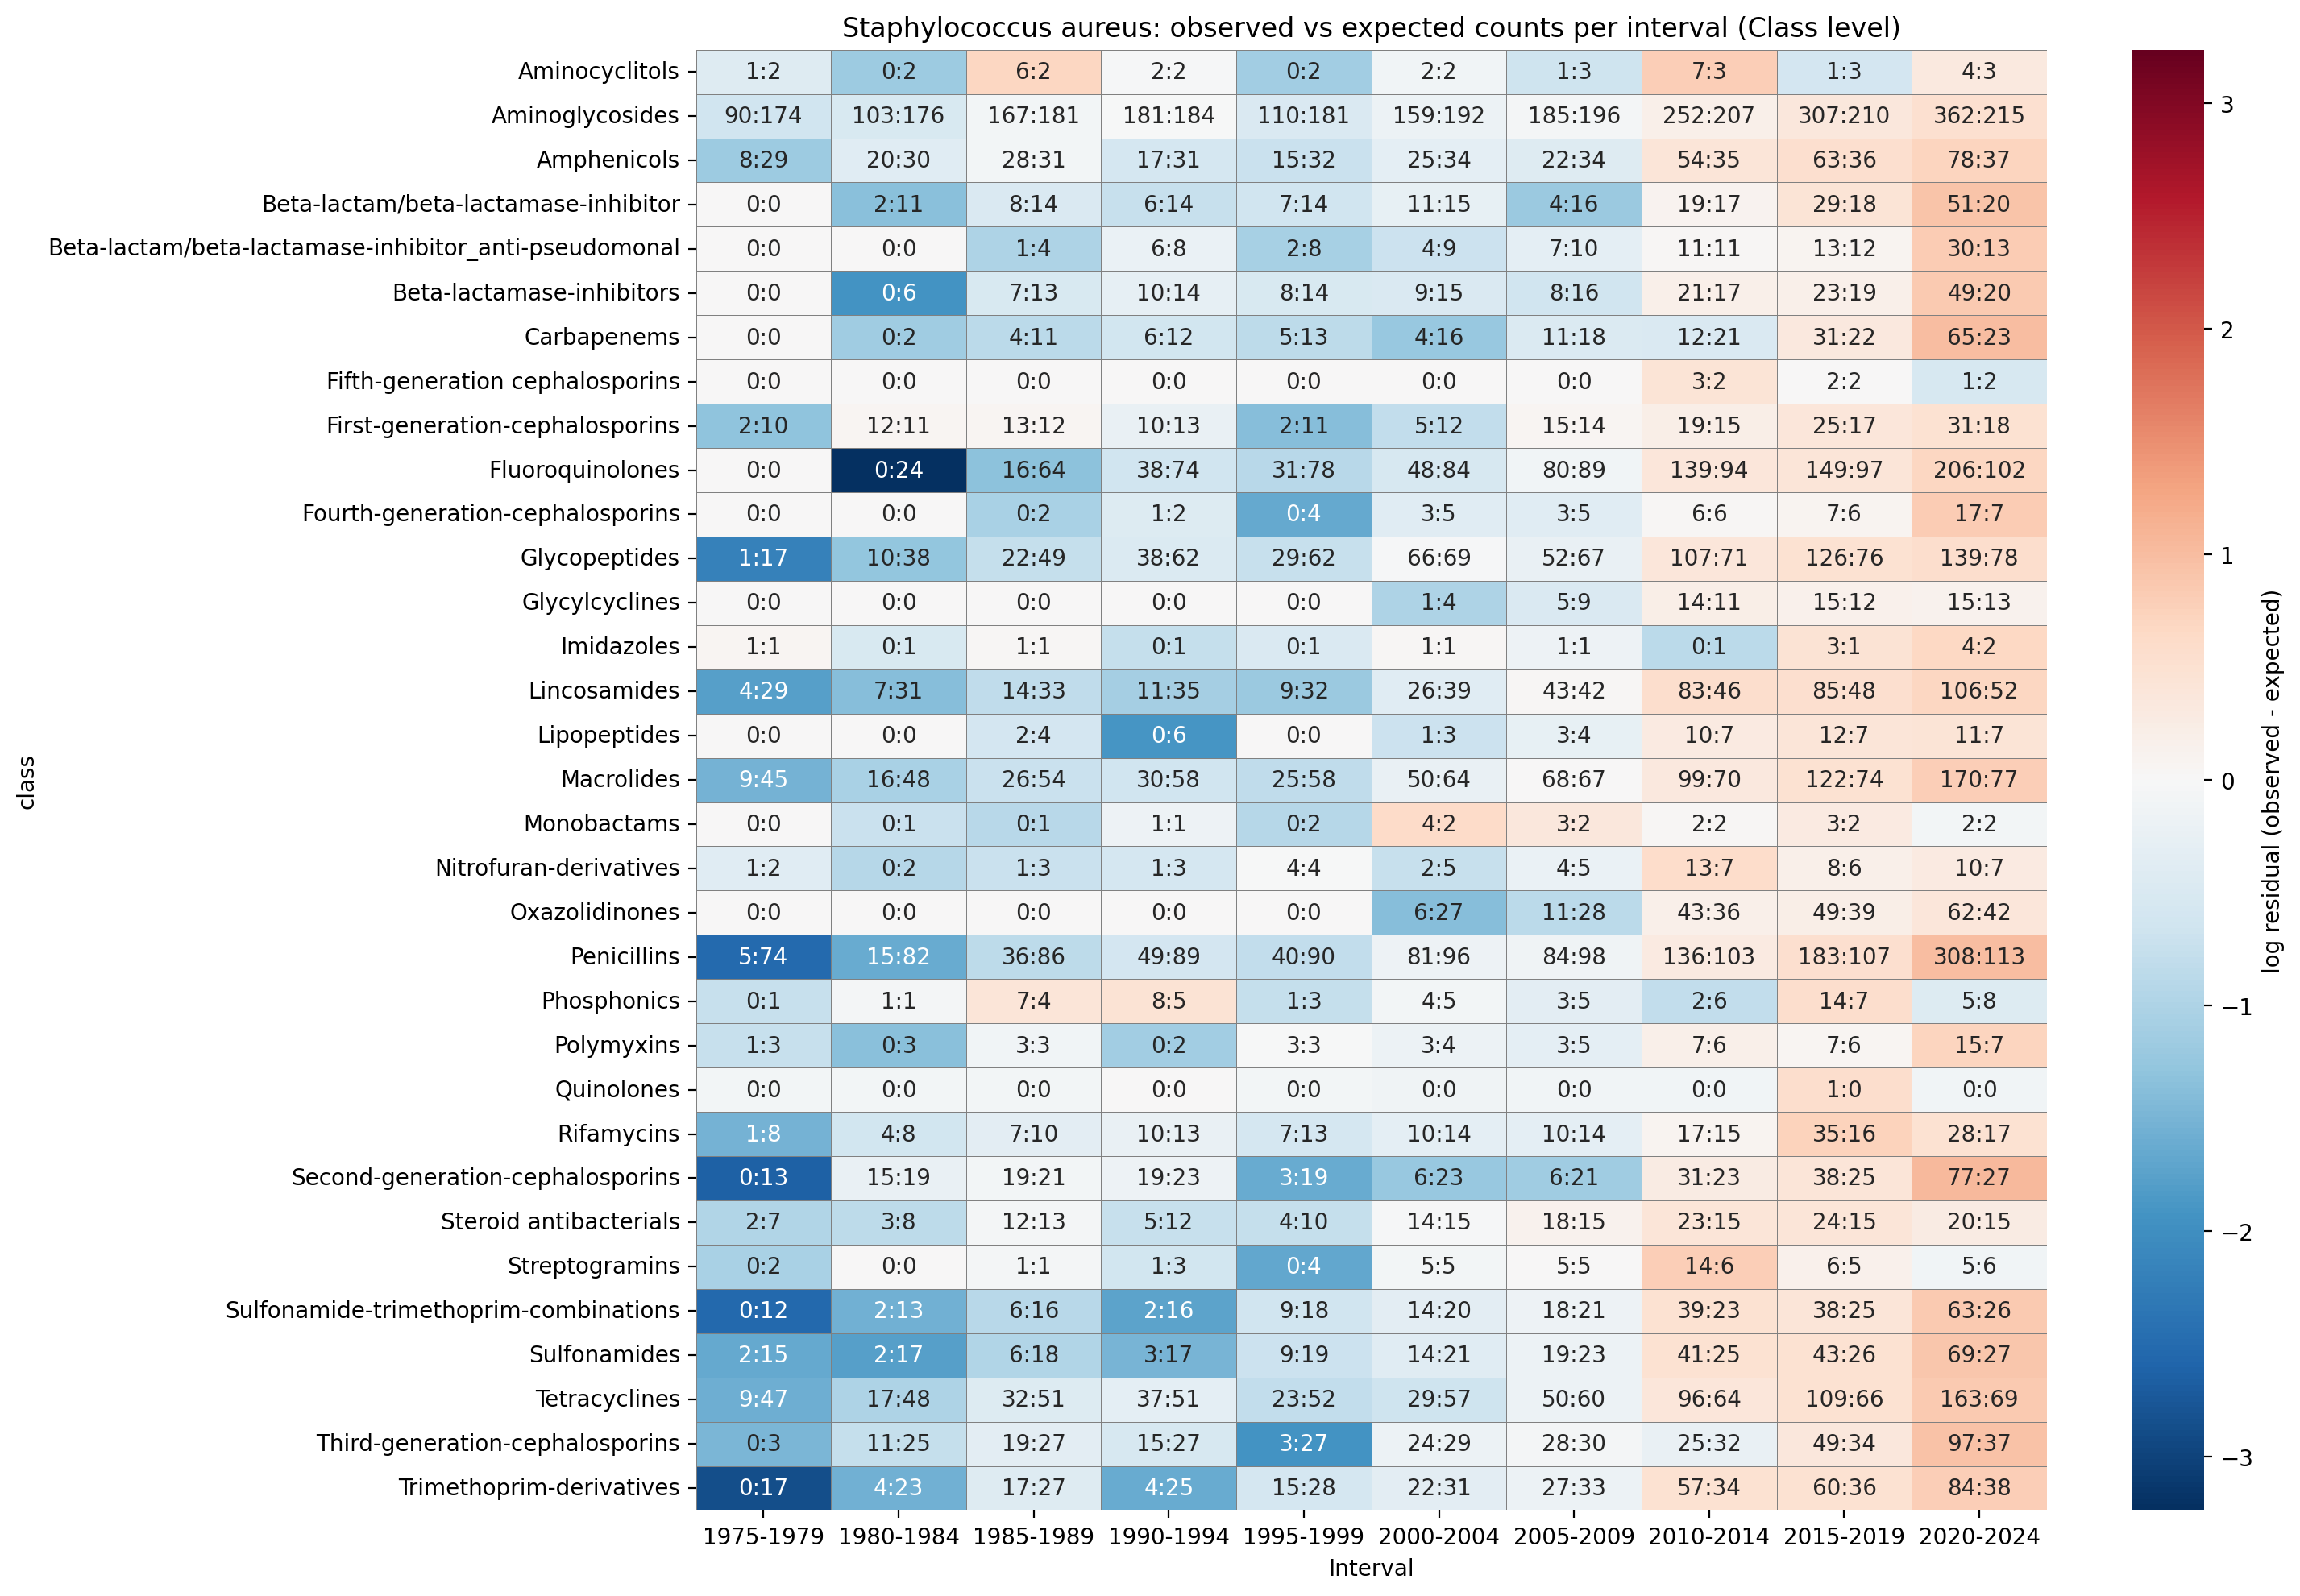

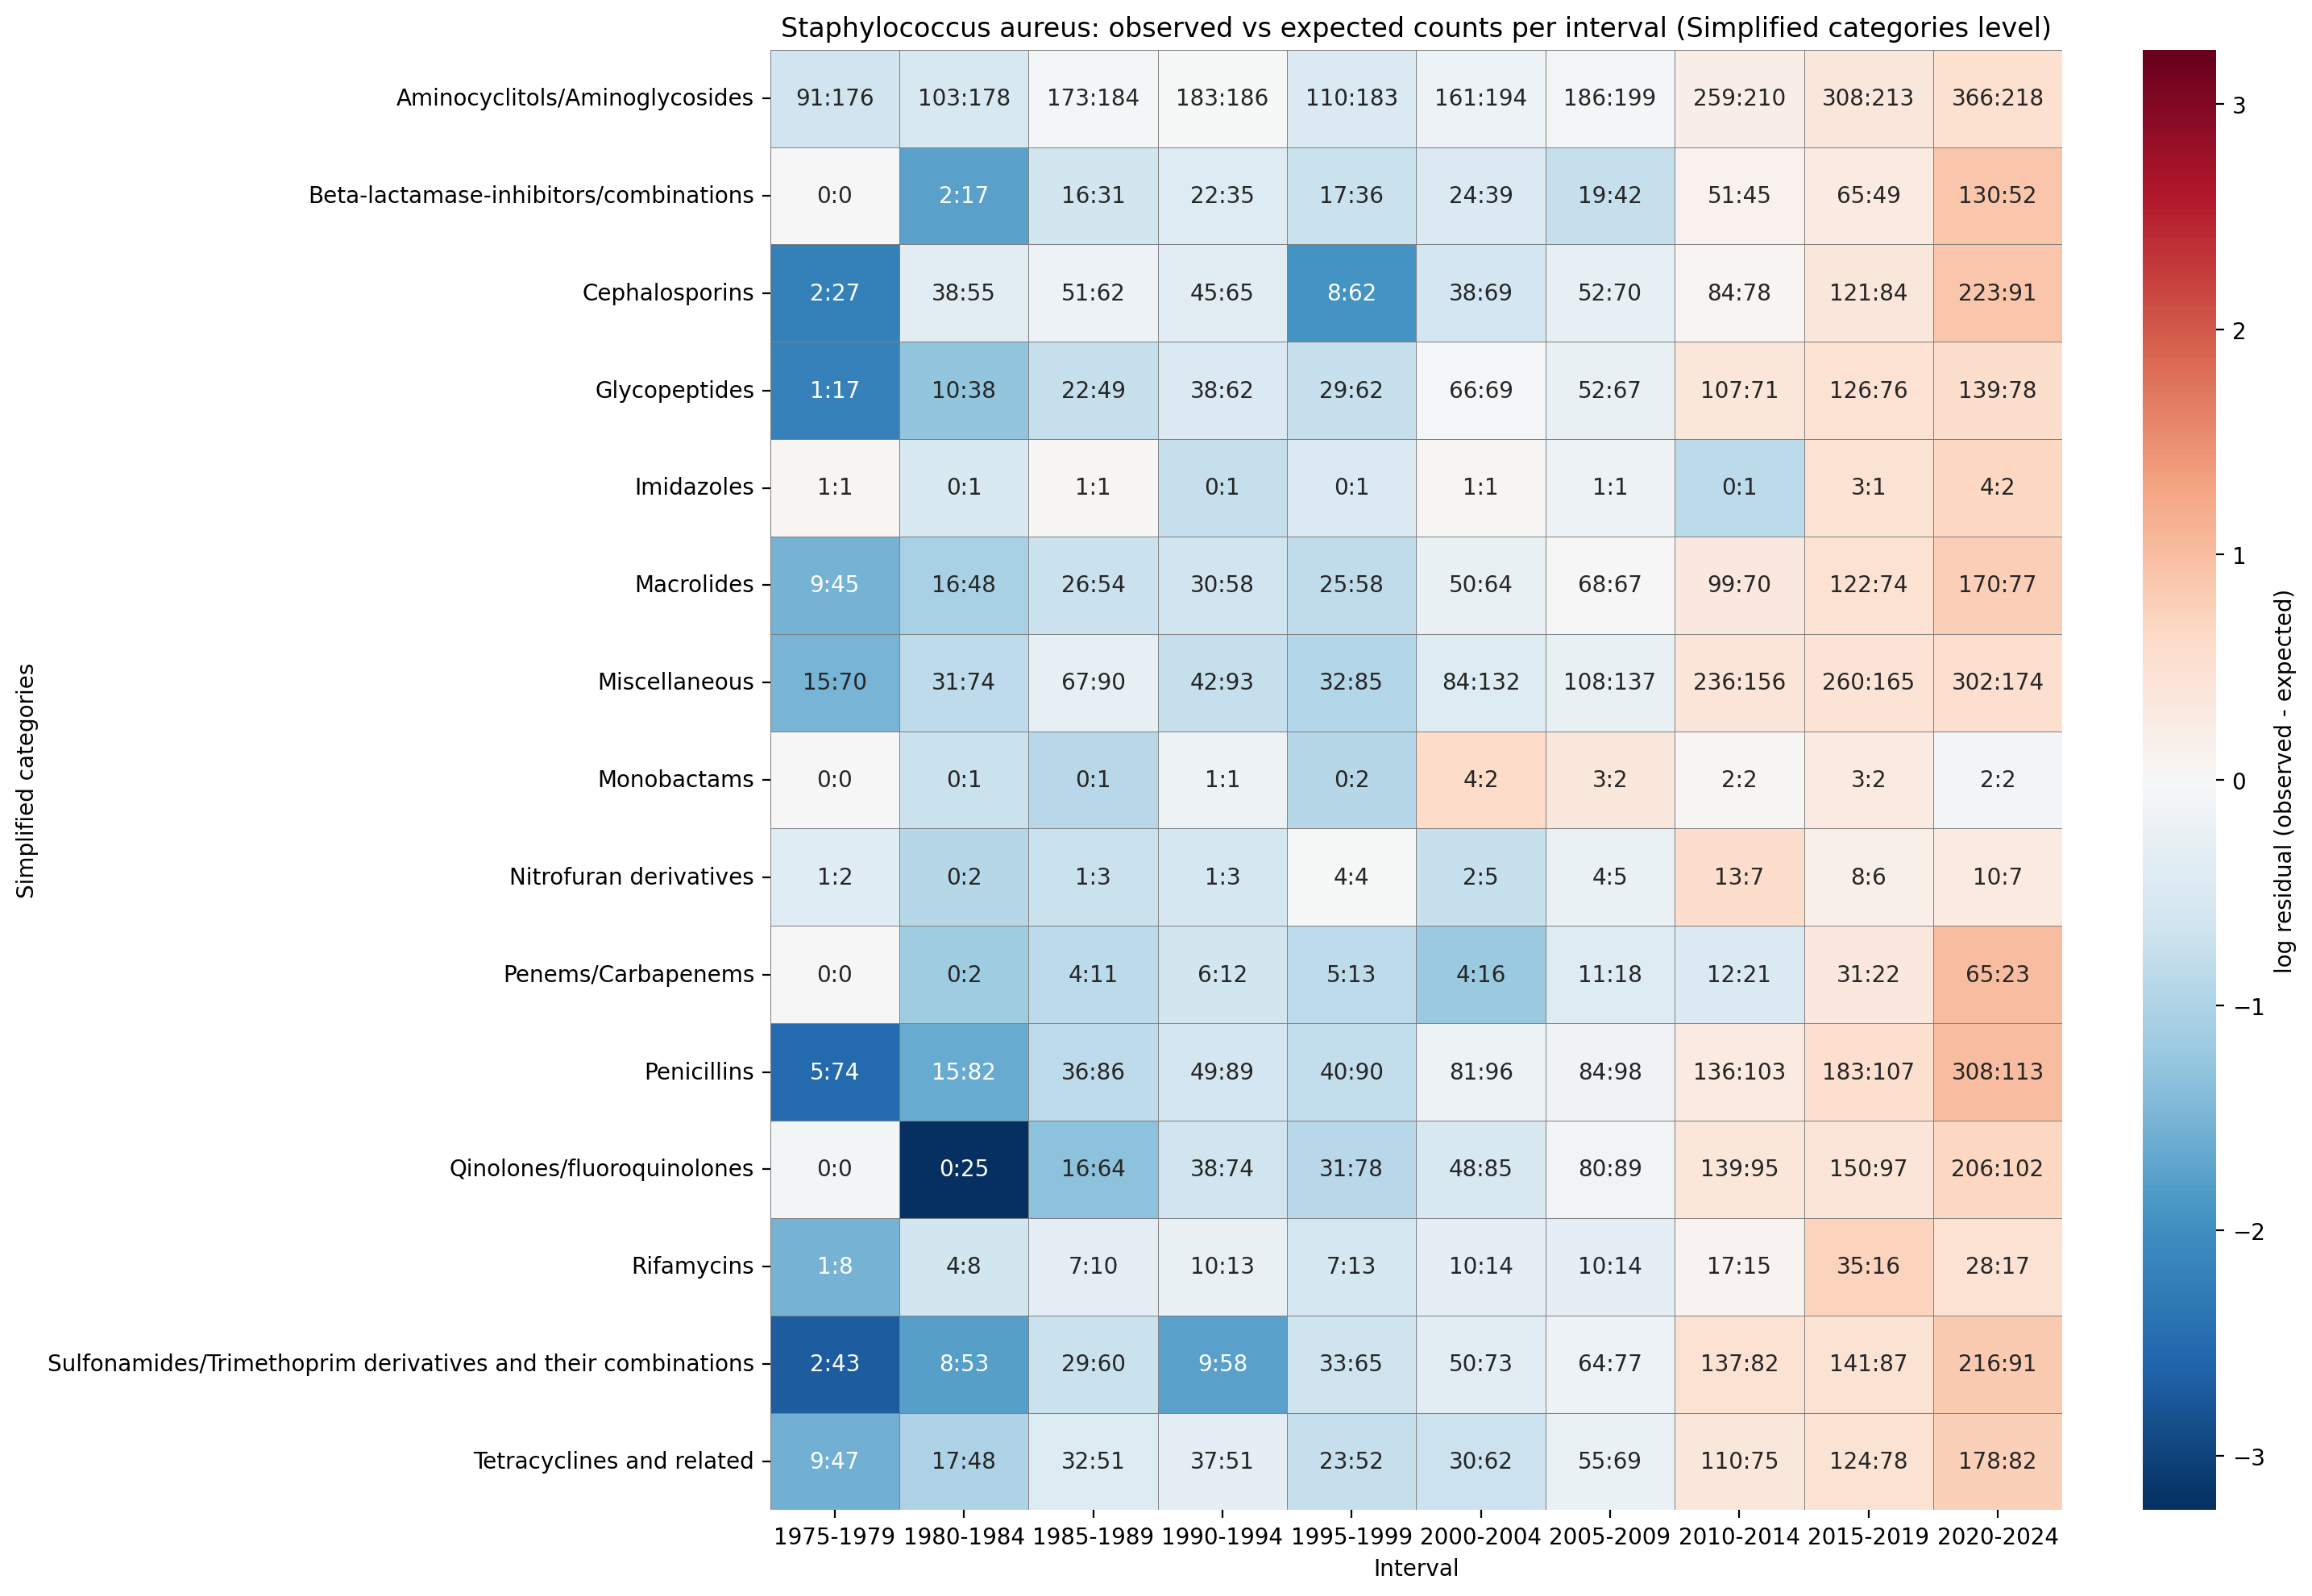

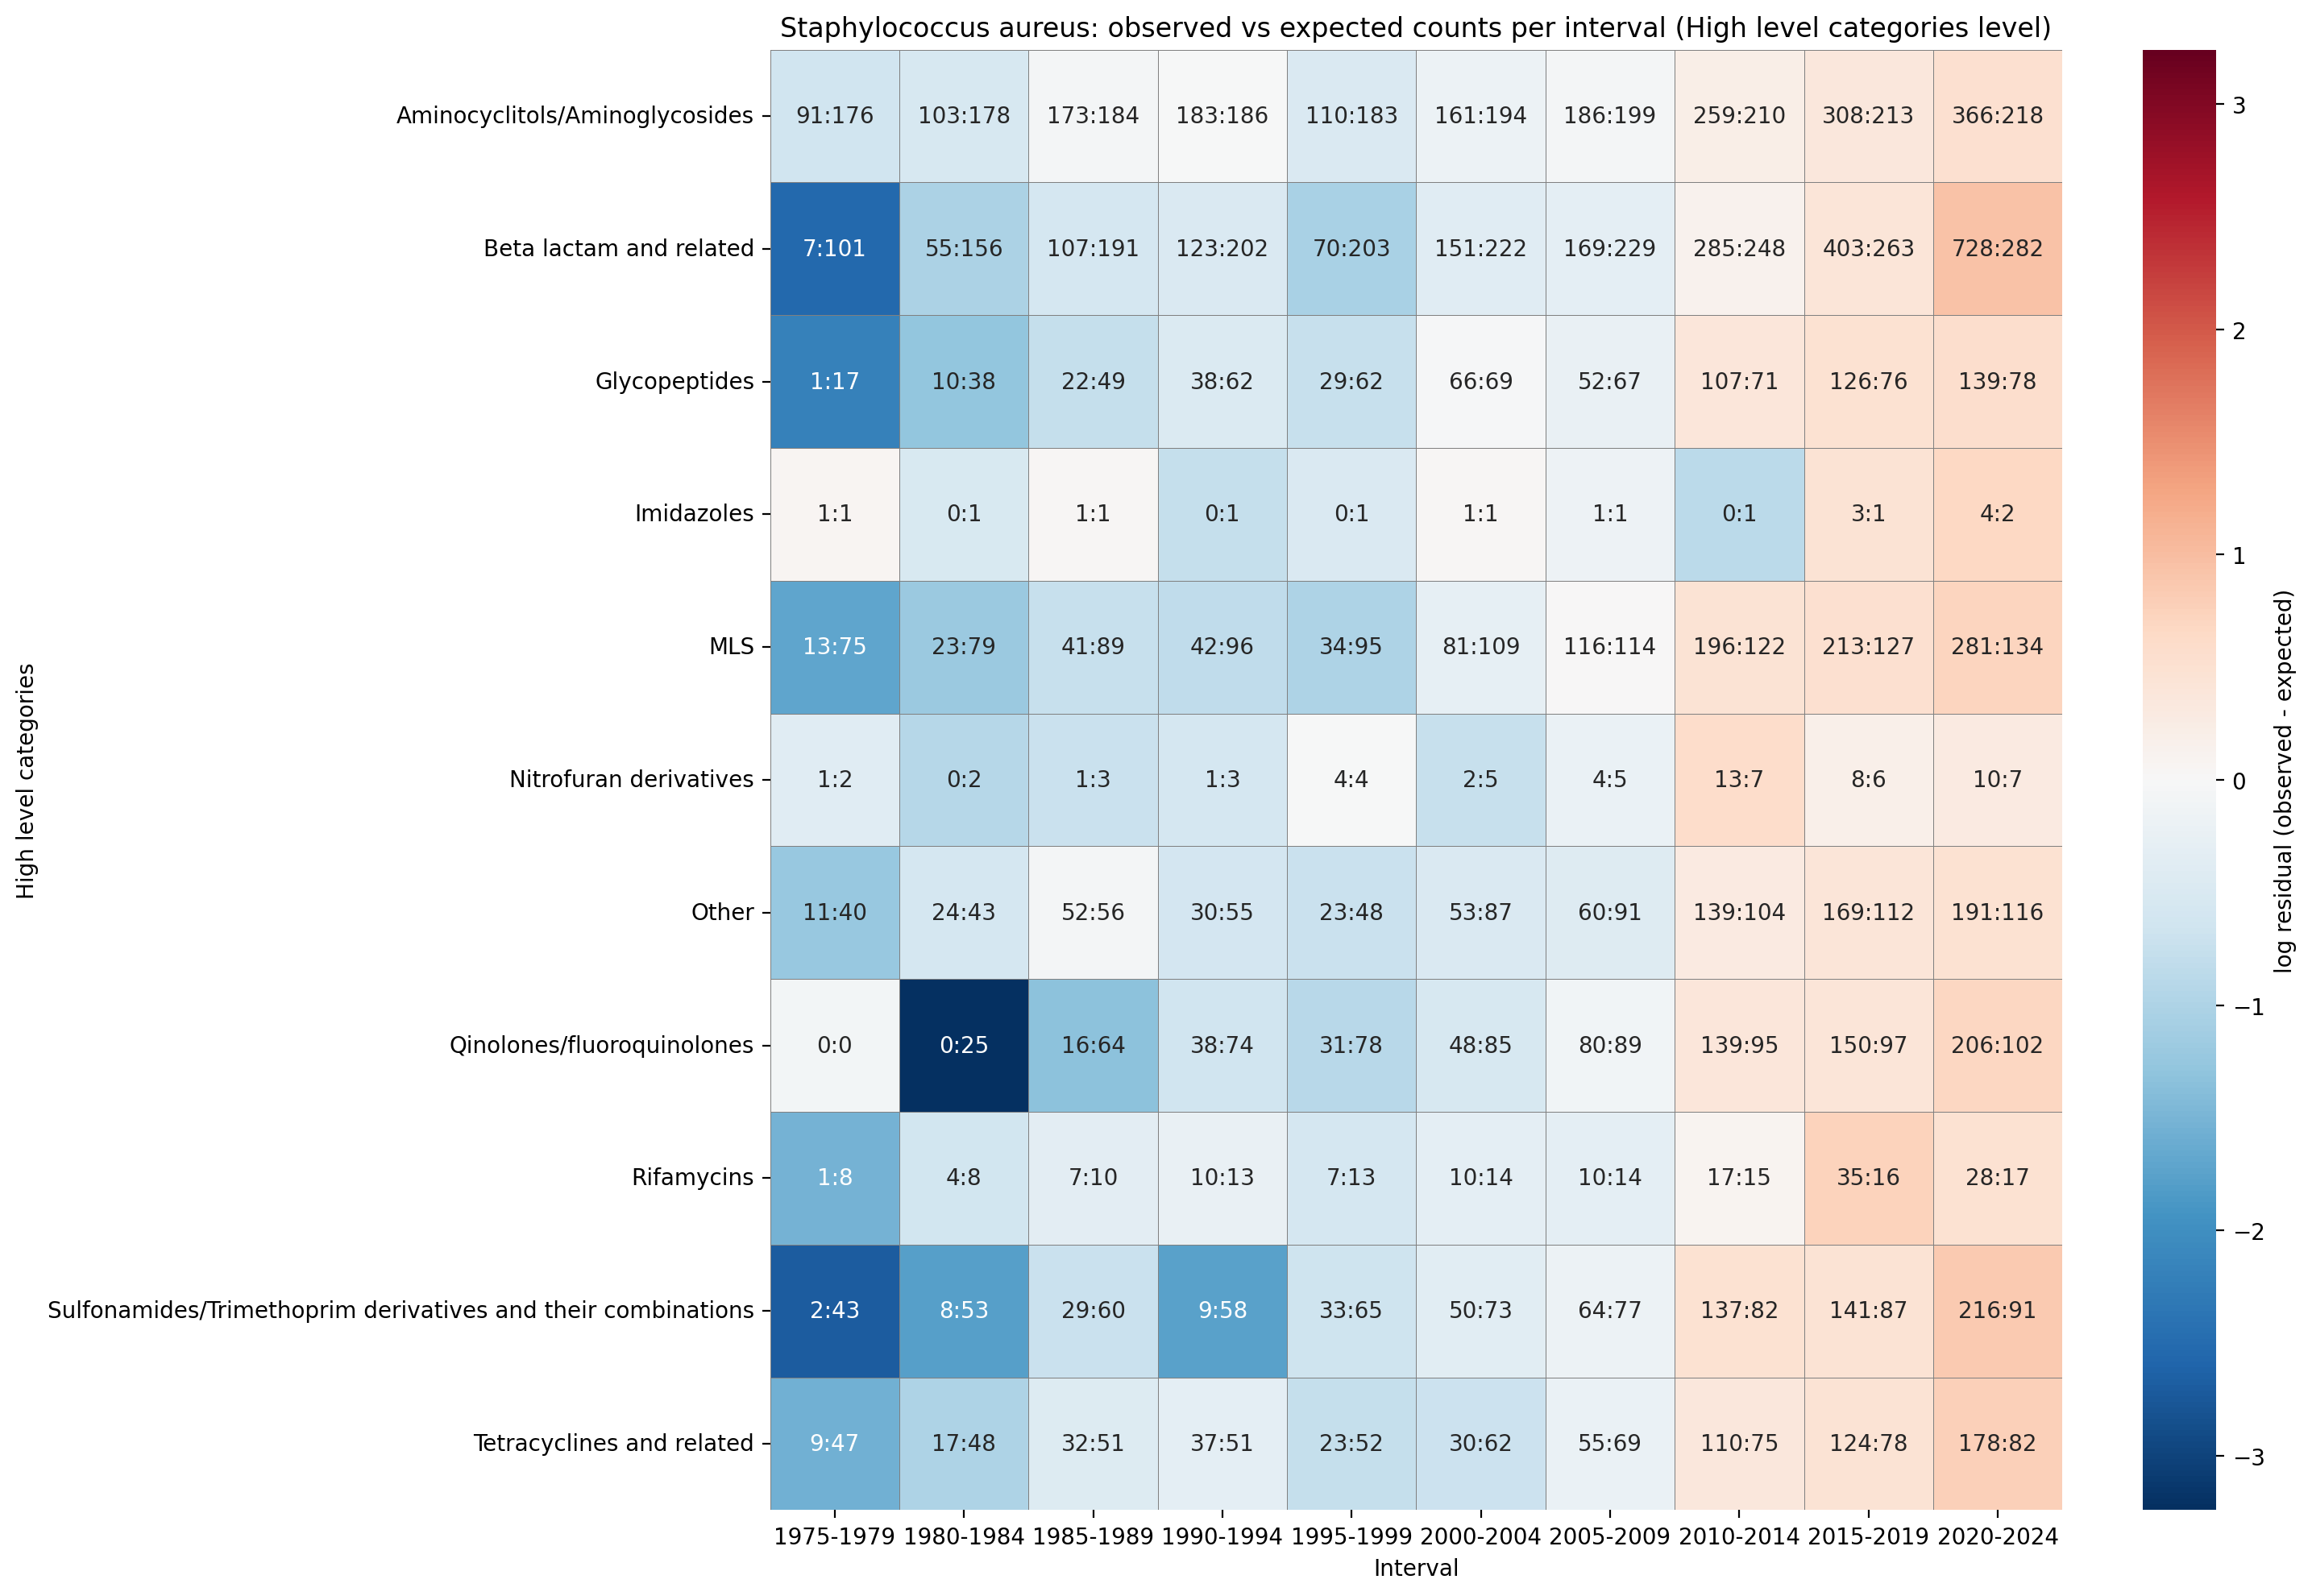

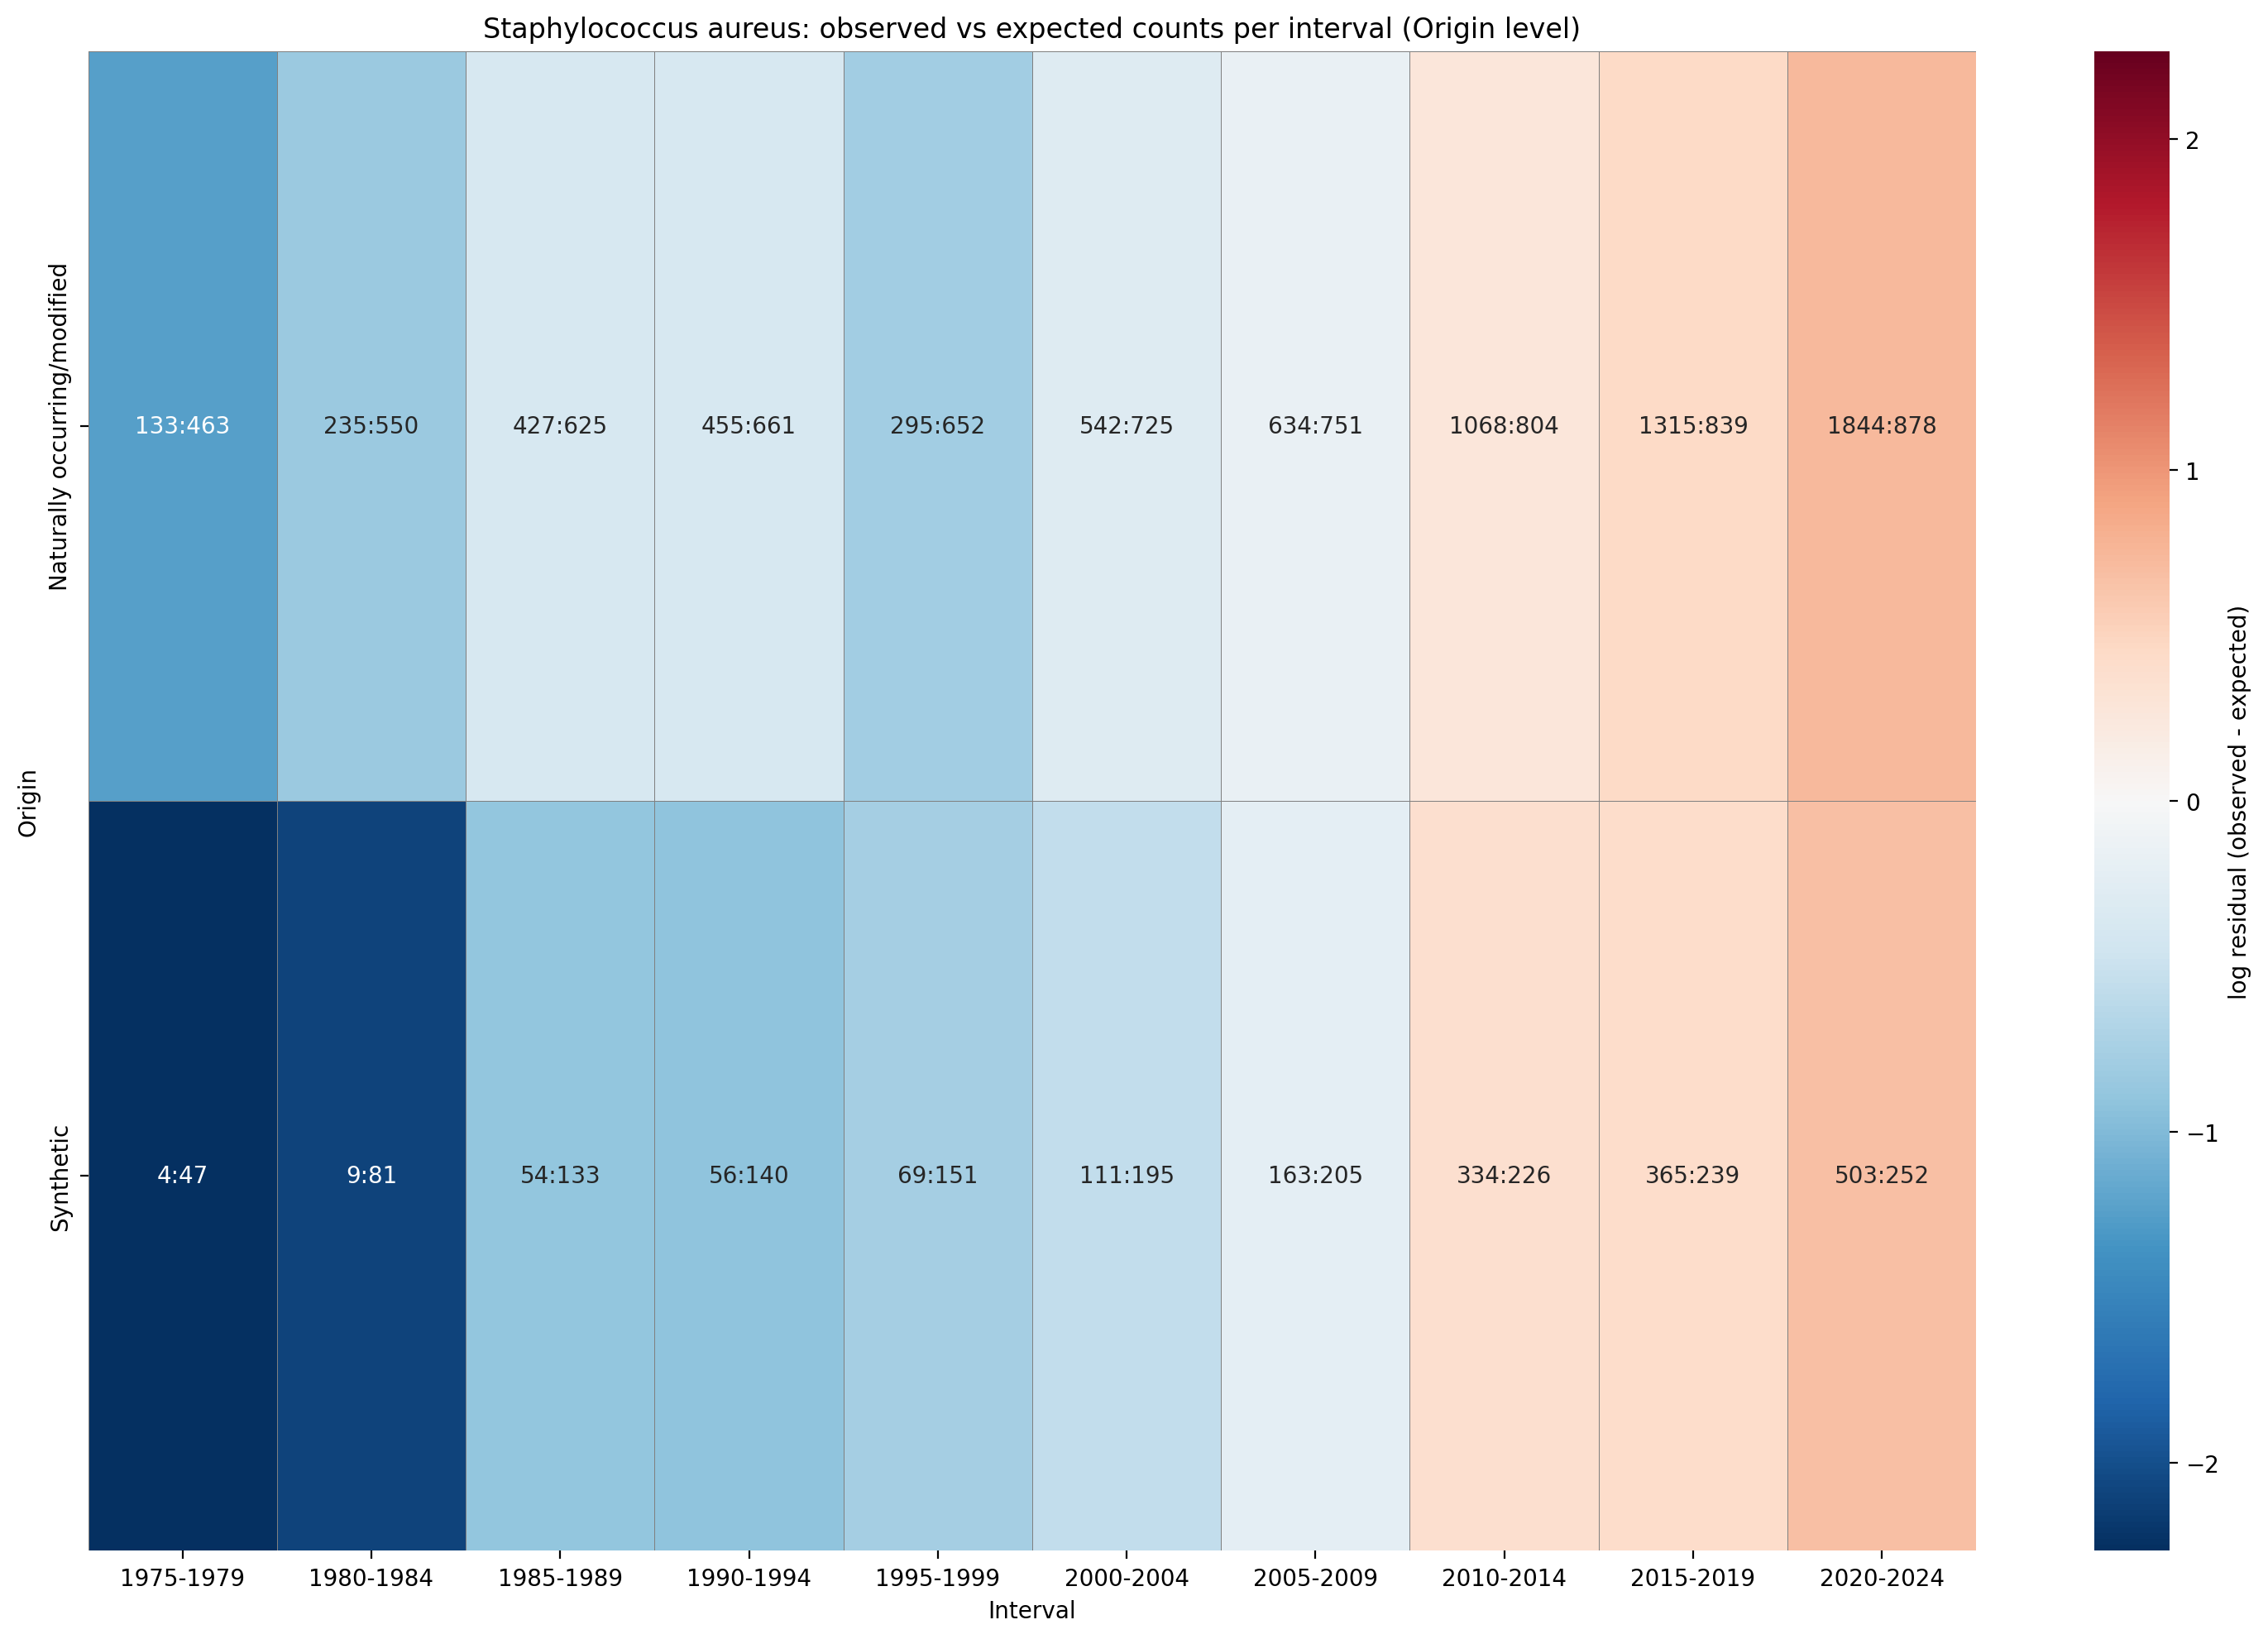

In [19]:
class_columns = ['Class', 'Simplified categories', 'High level categories', 'Origin']
for class_column in class_columns:
    plot_heatmap_counts_vs_expected_class(
        marg_cl,
        pathogen,
        class_column=class_column,
        class_df=antibiotics_df,
        figsize=(15, 10)
    )


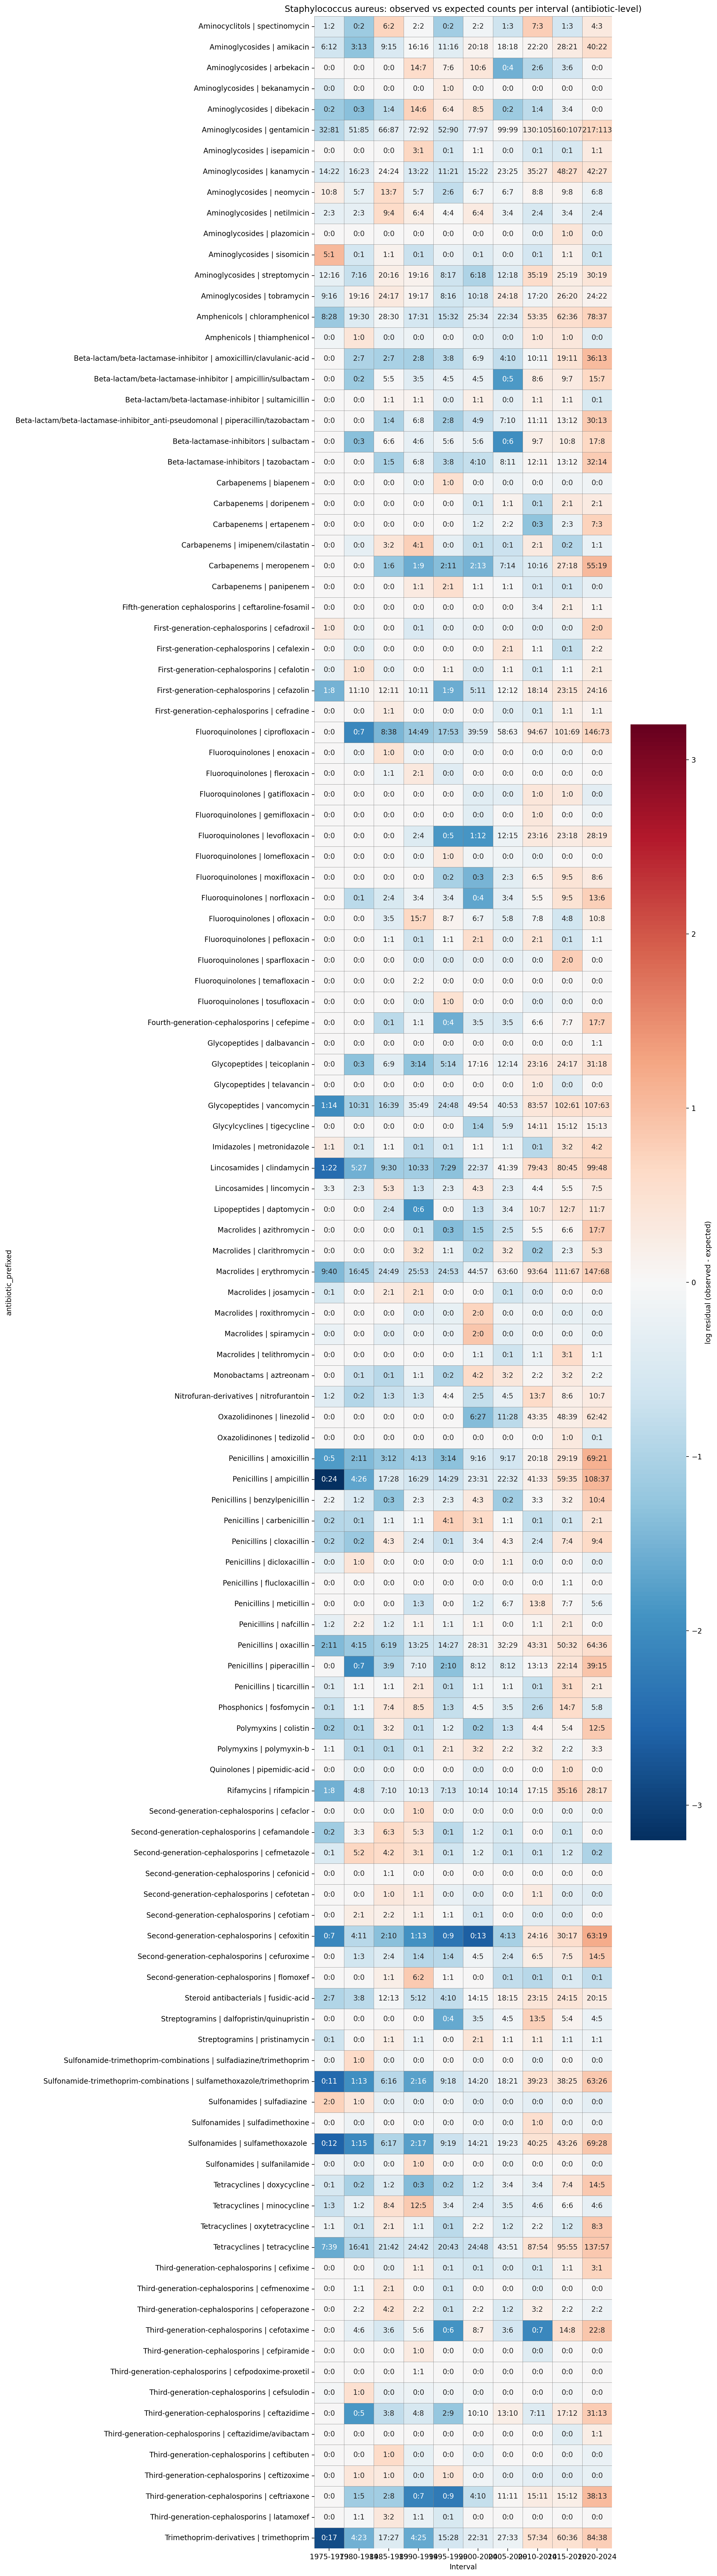

In [20]:
# Antibiotic-level heatmap
plot_heatmap_counts_vs_expected_antibiotic(
    marg_ab,
    pathogen,
    class_df=antibiotics_df,
    figsize=(14, 50)
)



Sampled pathogen (log-weighted): Staphylococcus aureus


<Axes: xlabel='end_date'>

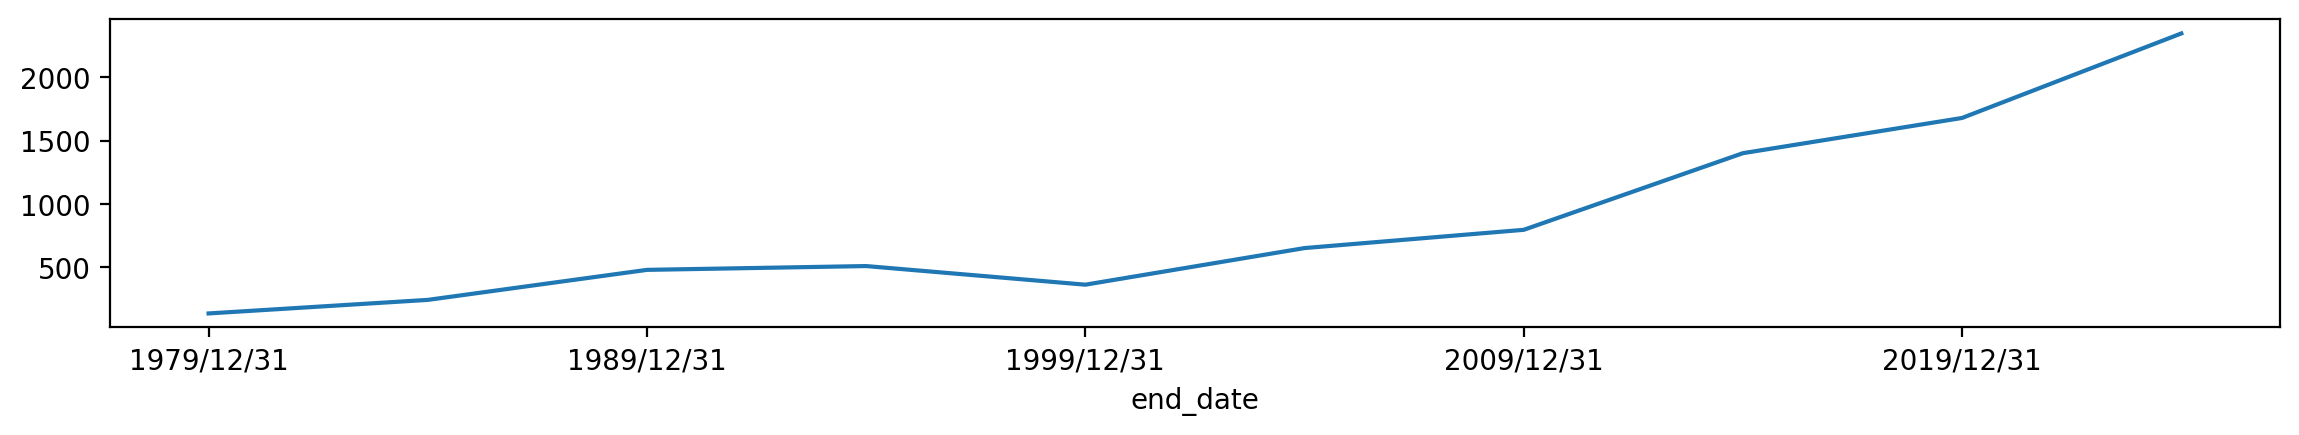

In [21]:
print(f"Sampled pathogen (log-weighted): {pathogen}")

# Plot heatmaps
df = amr_df[amr_df['pathogen'] == pathogen]
df.groupby('end_date')['count'].sum().plot(figsize=(14, 2))


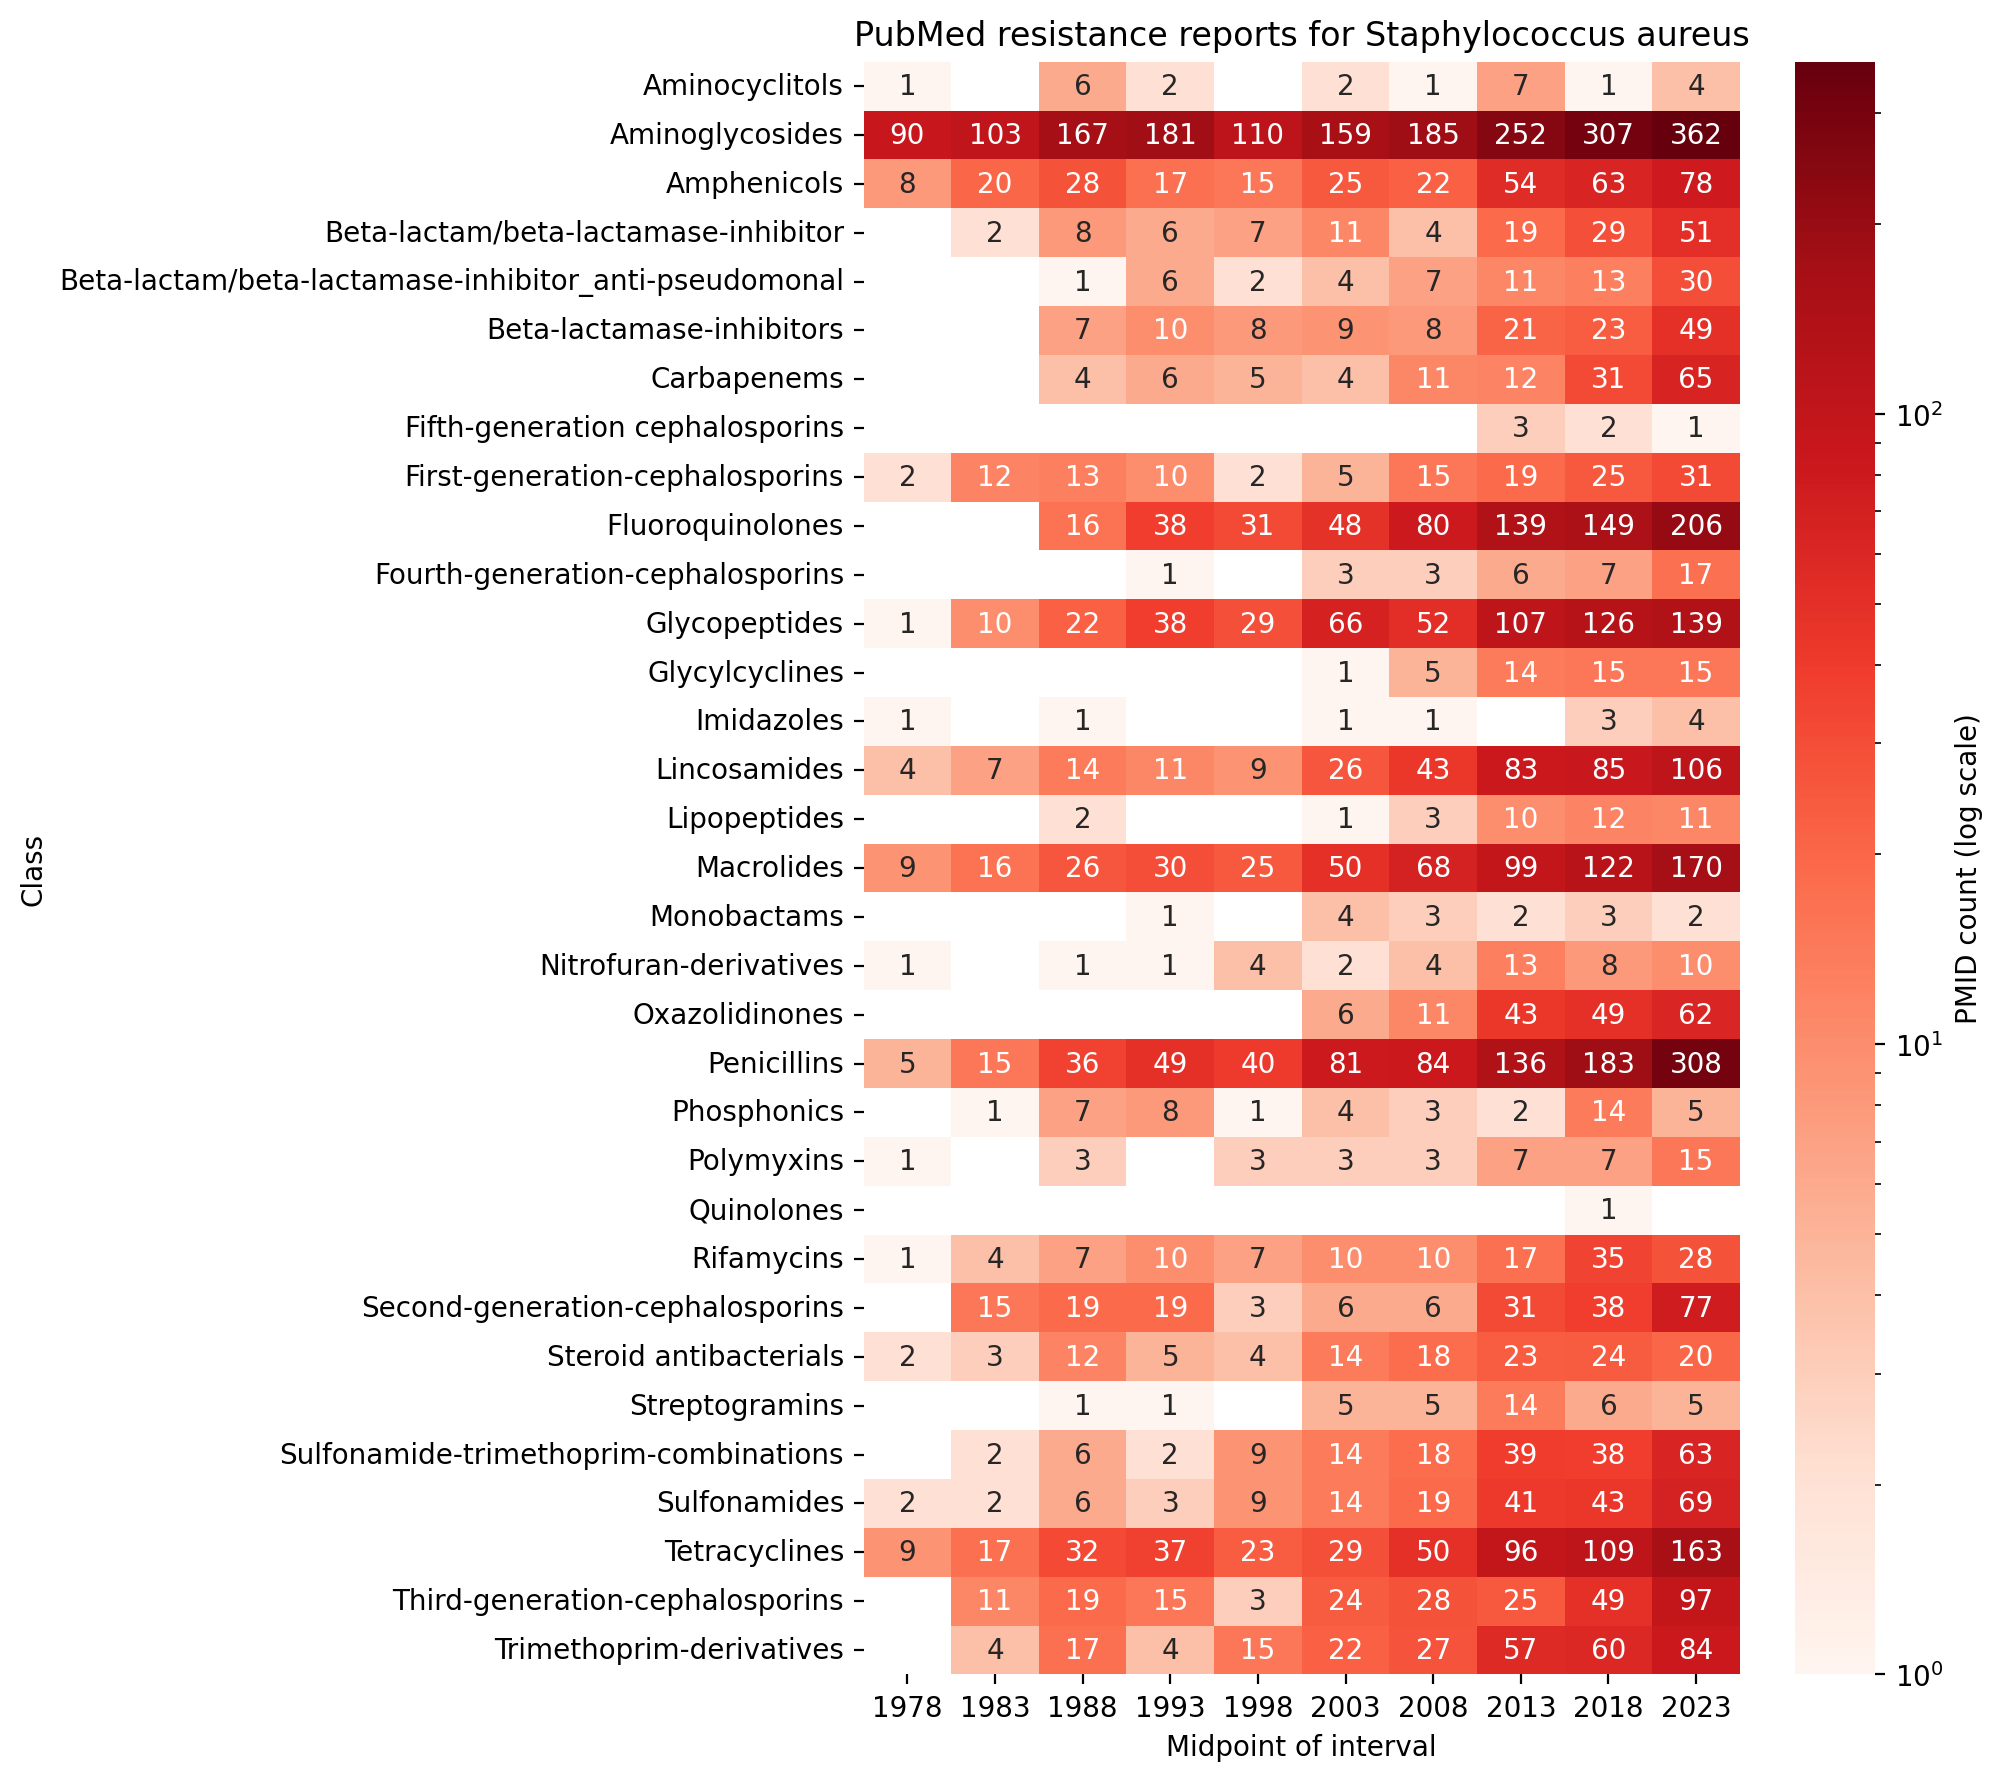

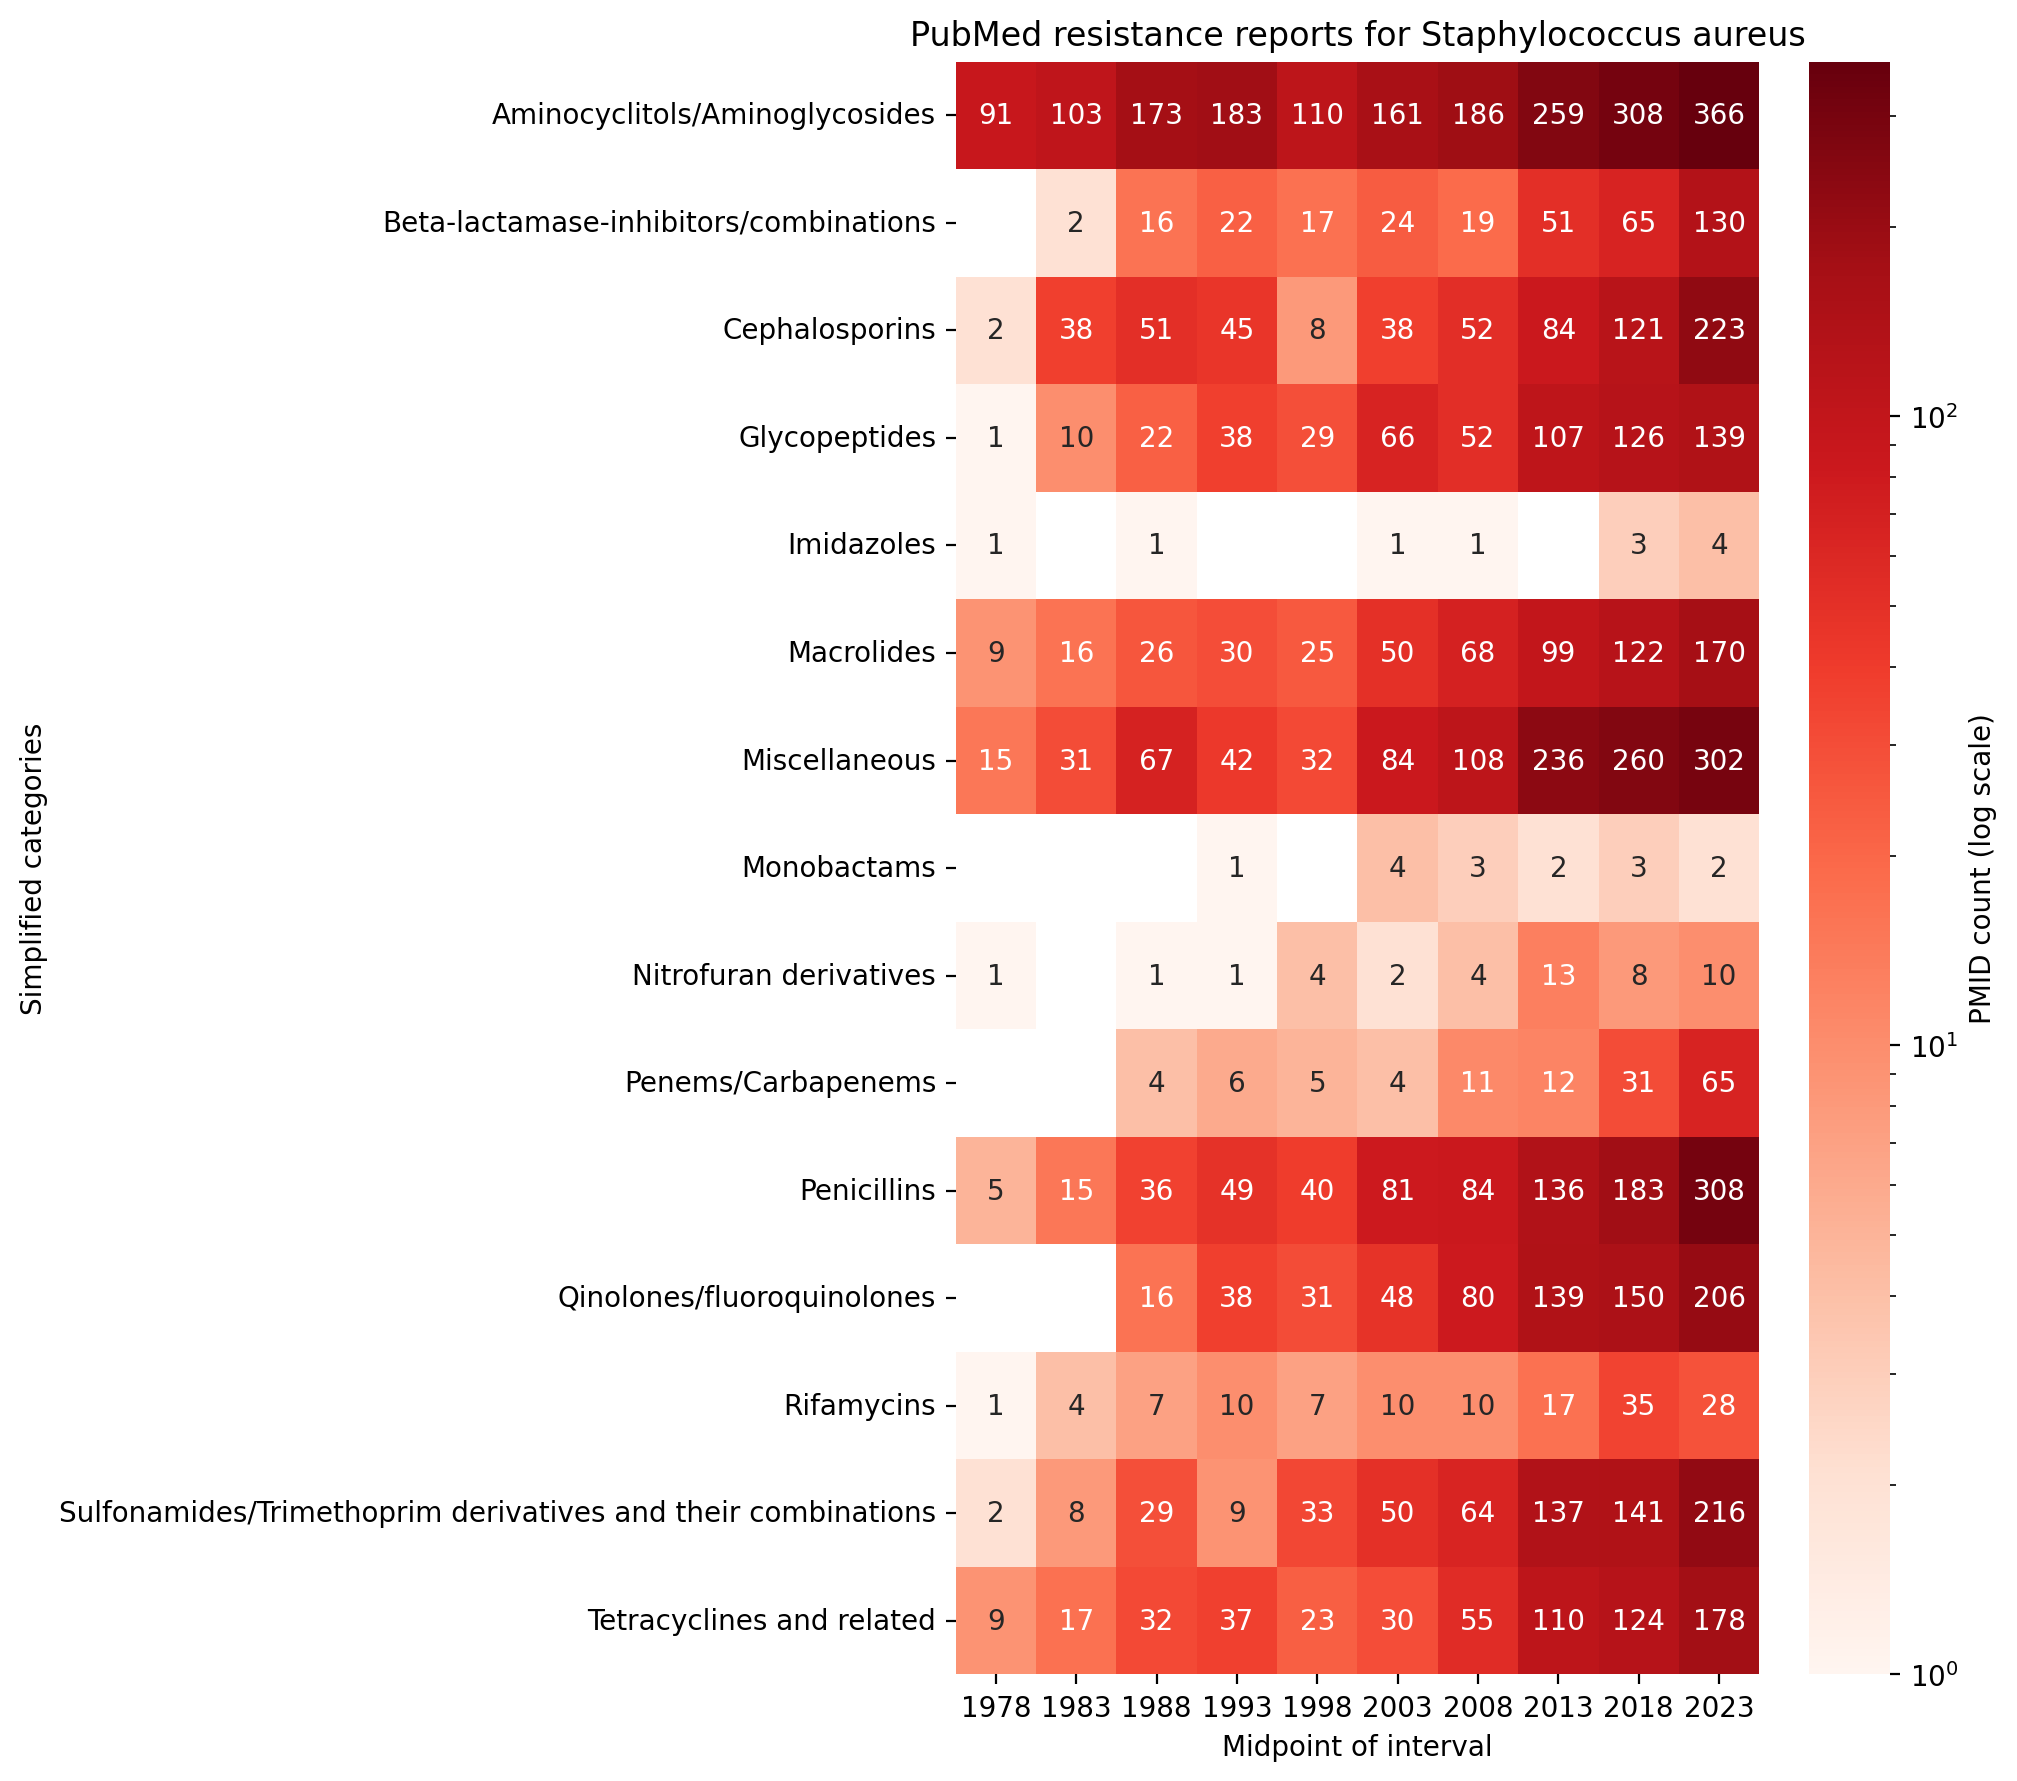

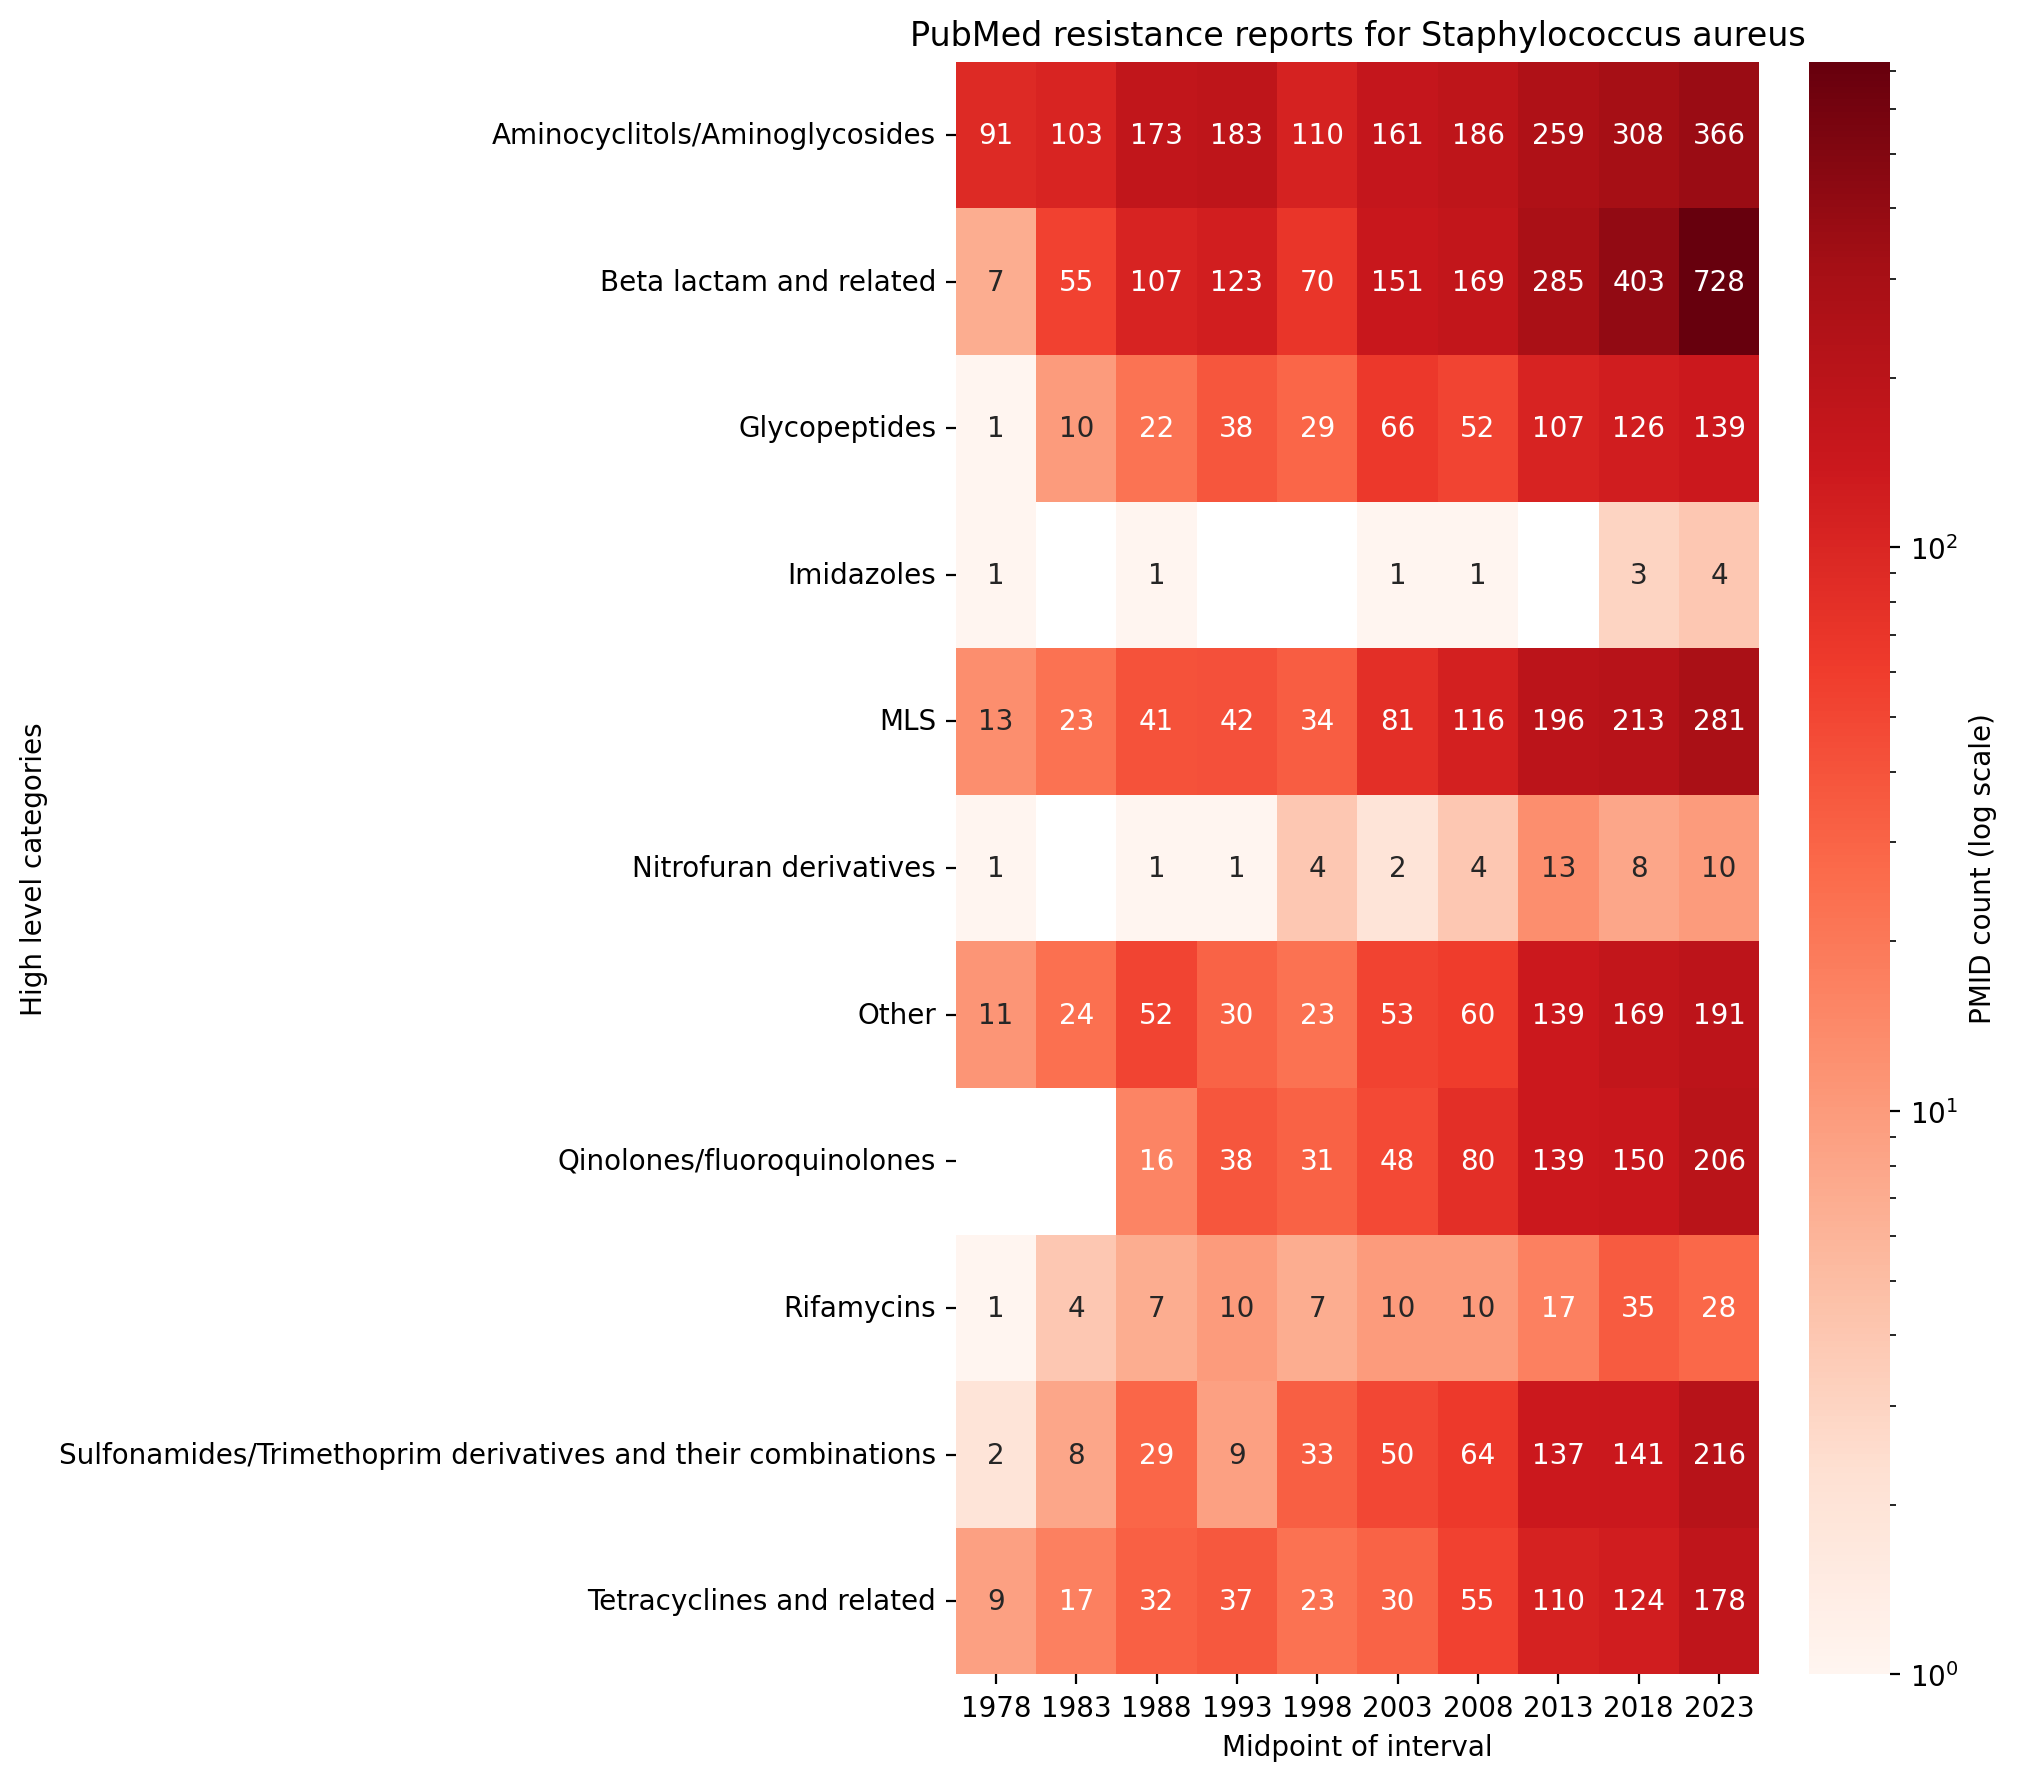

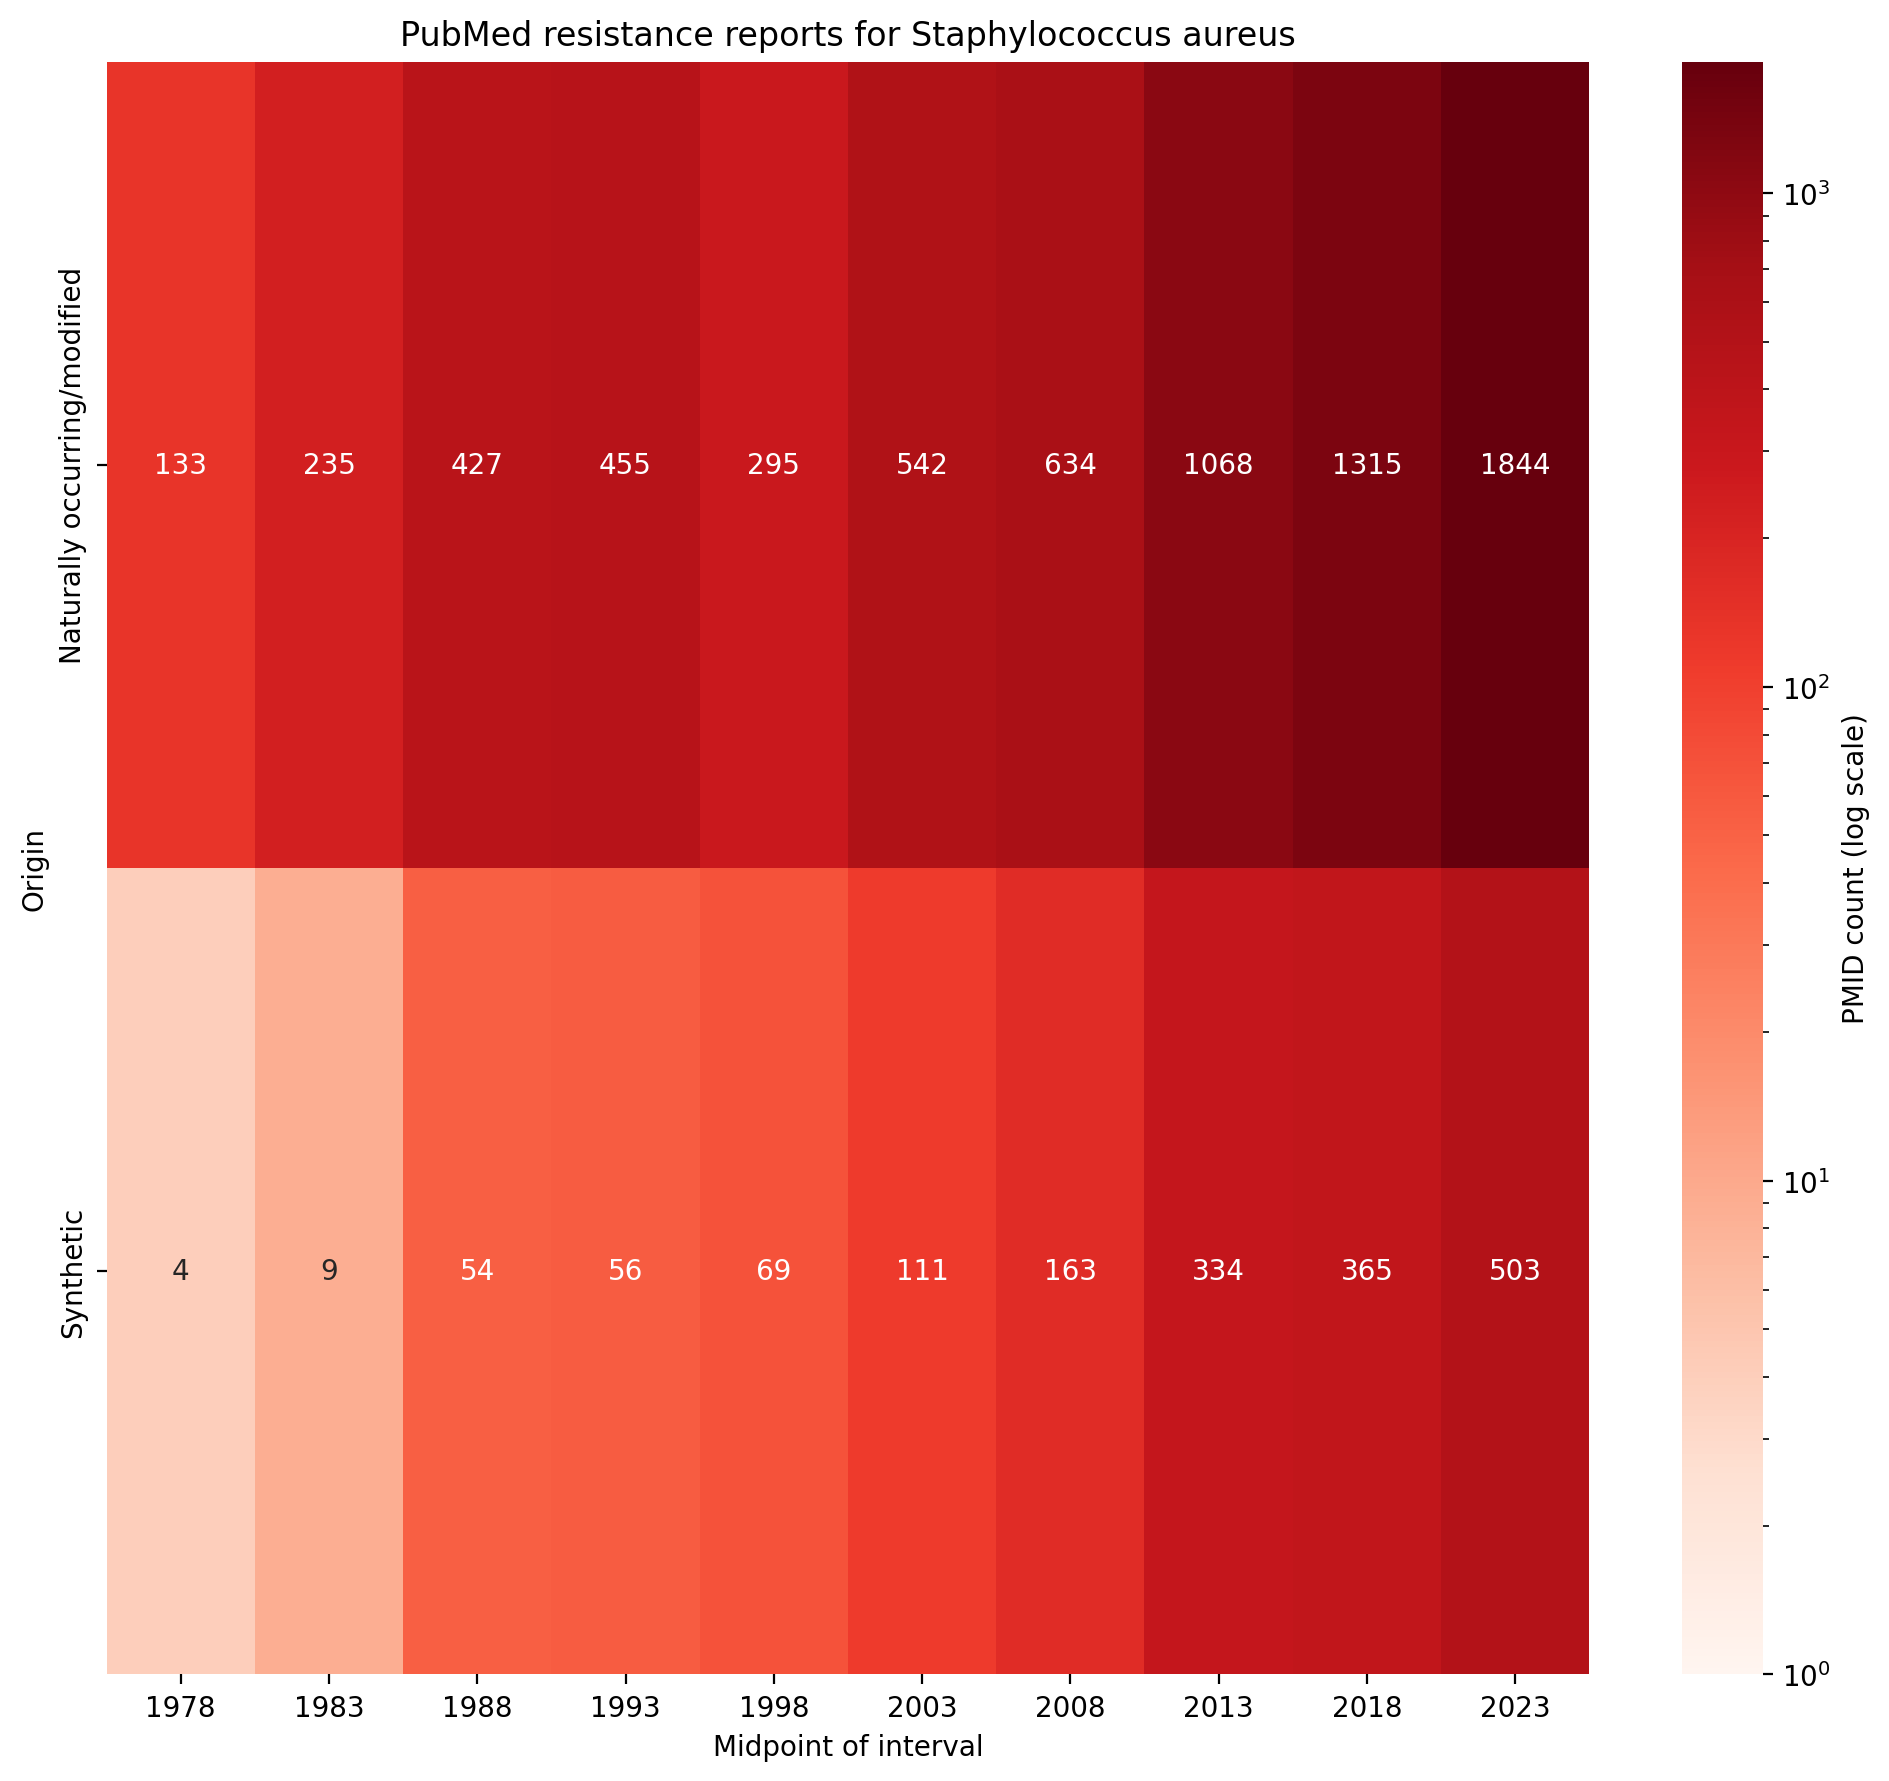

In [ ]:
class_columns = ['Class', 'Simplified categories', 'High level categories', 'Origin']
for class_column in class_columns:
    plot_heatmap_for_pathogen(
        amr_df, 
        pathogen,
        class_df=antibiotics_df, 
        group_column=class_column,
        show_only_class=True, 
        sort_by_frequency=False, 
        figsize=(10,9))


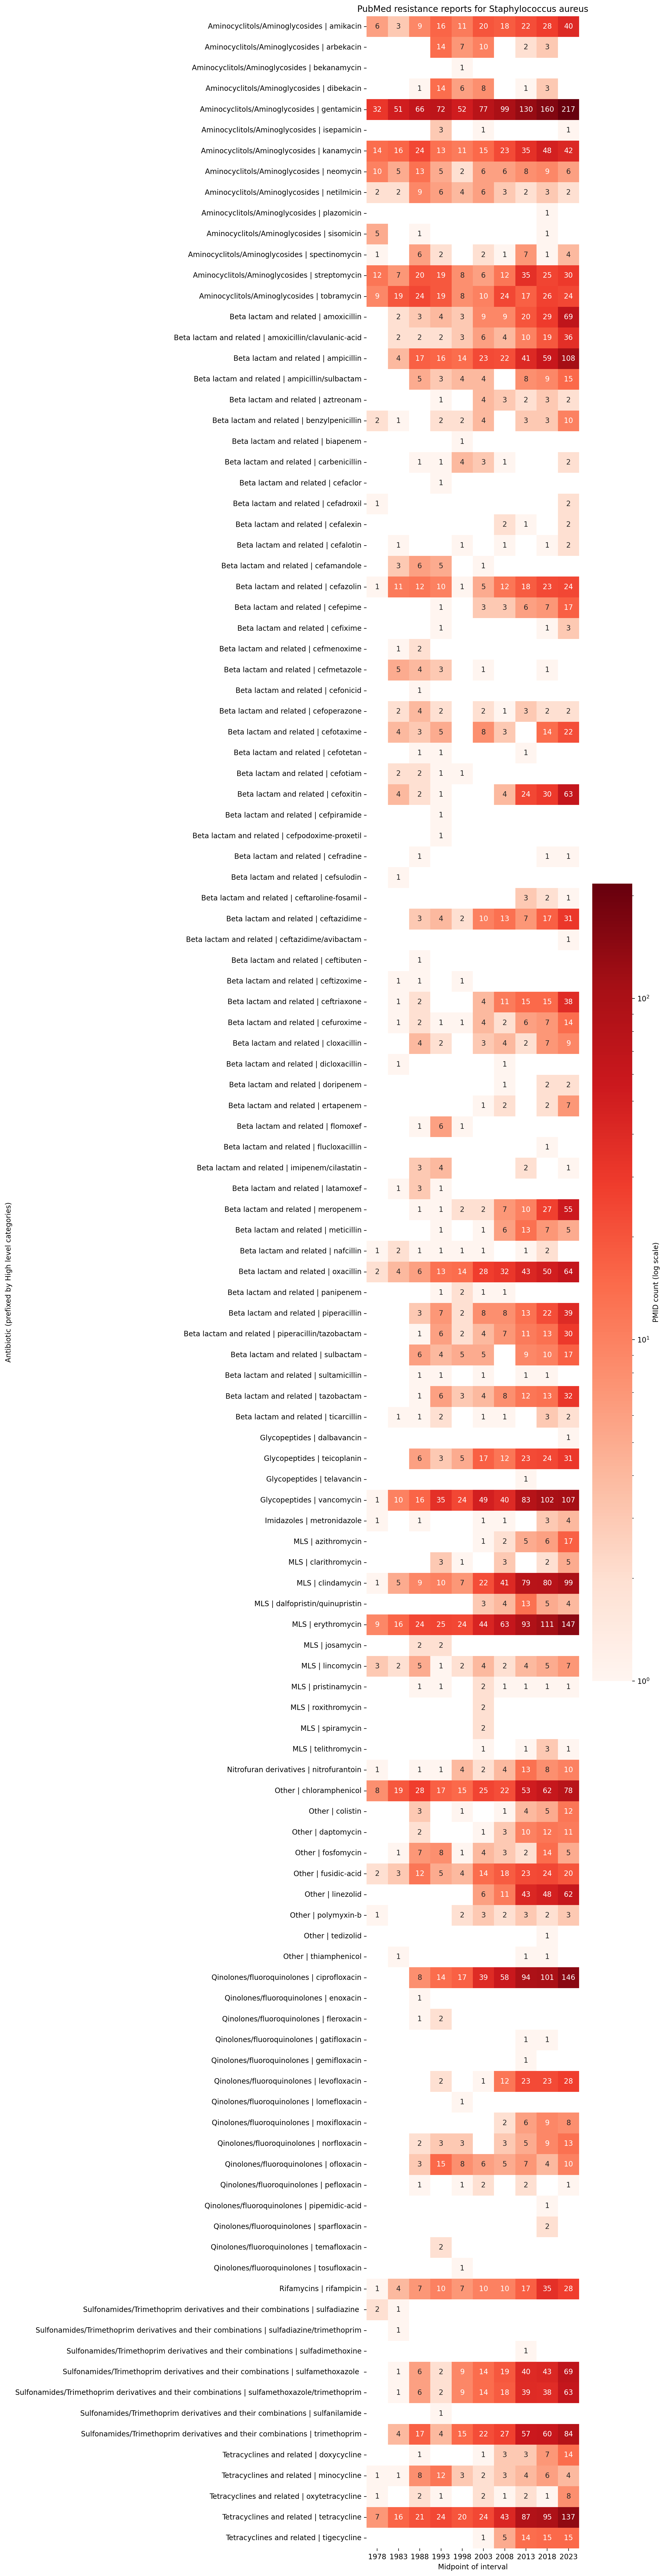

In [23]:
class_columns = ['Class', 'Simplified categories', 'High level categories', 'Origin']
plot_heatmap_for_pathogen(amr_df, pathogen, 
                          class_df=antibiotics_df, group_column='High level categories', 
                          show_only_class=False, figsize=(13,50))

---